# 06 – Frozen ACT-NER: post-hoc diagnostic evaluation

What does the newly frozen model achieve on the historical 112-document test? This population has informed earlier research decisions and is diagnostic, not untouched confirmation. No model, threshold or calibration map is fitted in this notebook.

In [1]:
from pathlib import Path
import os, sys, json, time
PROJECT_ROOT=Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
for _folder in ("artifacts", "figures/PNG", "figures/PDF", "Models", "Predictions", "Reports"):
    (PROJECT_ROOT / _folder).mkdir(parents=True, exist_ok=True)    # output folders of a fresh clone
assert (PROJECT_ROOT/"dataset").is_dir()
sys.path.insert(0,str(PROJECT_ROOT/"src"))
os.environ["HF_HUB_OFFLINE"]="1"
os.environ["TOKENIZERS_PARALLELISM"]="false"
import numpy as np
import pandas as pd
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML
assert "Times New Roman" in {font.name for font in font_manager.fontManager.ttflist}
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,
    "axes.titlesize":20,"axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,
    "legend.fontsize":18,"figure.dpi":350,"savefig.dpi":350,"figure.facecolor":"white"})
pd.set_option("display.max_rows",None)
pd.set_option("display.max_columns",None)
pd.set_option("display.max_colwidth",None)
torch.set_num_threads(4)

The final evaluation proceeds under the recorded recognition–calibration trade-off: development recognition criteria were satisfied, whereas accepted-entity ECE increased relative to prior ACT-NER. The ECE criterion remains unsatisfied; neither calibration nor predictive settings are revised here.

In [2]:
from refinement_final_evaluation import verify_evaluation_scope
development_criteria=verify_evaluation_scope(PROJECT_ROOT)

In [3]:
import joblib, contextlib, io
from refinement_experiment import RUN,SEEDS,MODELS,load_model,digest,verify_protected,prediction_diagnostics
from refinement_analysis import summarize_seeds,subgroup_evidence,paired_evidence
from prospective_data import dependency_components
from core import gold_for_metrics
from act_ner import build_candidate_bundle

In [4]:
from scipy import stats
from core import PREDICTION_COLUMNS,load_processed,normalize_surface
from prospective_model import score,strict_metrics
from refinement_model import decode
from prospective_calibration import apply_confidence

In [5]:
def counts_by_document(sentences, entities, prediction, documents):
    gold = gold_for_metrics(entities)
    columns = ["sentence_id","char_start","char_end"]
    result = []
    gs = {d: set(frame[columns+["entity_type"]].itertuples(index=False,name=None))
          for d,frame in gold.groupby("document_id")}
    ps = {d: set(frame[columns+["predicted_type"]].itertuples(index=False,name=None))
          for d,frame in prediction.groupby("document_id")}
    for document in documents.document_id:
        g,p = gs.get(document,set()), ps.get(document,set())
        result.append([len(g&p),len(g),len(p)])
    values = pd.DataFrame(result,columns=["tp","gold","predicted"])
    values["group"] = documents.dependency_group.to_numpy()
    return values.groupby("group",sort=True)[["tp","gold","predicted"]].sum().to_numpy(float)

In [6]:
def f1_counts(values):
    return np.divide(2*values[...,0], values[...,1]+values[...,2],
                     out=np.zeros_like(values[...,0]),where=(values[...,1]+values[...,2])>0)

In [7]:
def holm(values):
    values = np.asarray(values,float)
    order = np.argsort(values)
    adjusted = np.empty_like(values)
    adjusted[order] = np.minimum(1,np.maximum.accumulate(values[order]*(len(values)-np.arange(len(values)))))
    return adjusted

In [8]:
def paired_evidence(predictions, sentences, entities, documents, comparisons, replicates=5000):
    counts = {name:np.stack([counts_by_document(sentences,entities,p,documents) for p in repeats.values()])
              for name,repeats in predictions.items()}
    rng = np.random.default_rng(9017)
    groups = next(iter(counts.values())).shape[1]
    weights = rng.multinomial(groups,np.full(groups,1/groups),size=replicates)
    switches = rng.integers(0,2,size=(replicates,groups))
    rows = []
    for left,right in comparisons:
        a,b = counts[left],counts[right]
        if len(b)==1 and len(a)>1: b=np.repeat(b,len(a),axis=0)
        if len(a)==1 and len(b)>1: a=np.repeat(a,len(b),axis=0)
        observed = float((f1_counts(a.sum(1))-f1_counts(b.sum(1))).mean())
        bootstrap = (f1_counts(np.einsum("bg,sgc->bsc",weights,a))-
                     f1_counts(np.einsum("bg,sgc->bsc",weights,b))).mean(1)
        difference = a-b
        swapped_a = b.sum(1)[None,:,:]+np.einsum("bg,sgc->bsc",switches,difference)
        swapped_b = a.sum(1)[None,:,:]-np.einsum("bg,sgc->bsc",switches,difference)
        random_delta = (f1_counts(swapped_a)-f1_counts(swapped_b)).mean(1)
        pvalue = (1+np.sum(np.abs(random_delta)>=abs(observed)))/(replicates+1)
        secondary = (f1_counts(a)-f1_counts(b)).mean(0)
        nonzero = secondary[np.abs(secondary)>1e-12]
        wilcoxon = float(stats.wilcoxon(nonzero).pvalue) if len(nonzero) else 1.0
        ranks = stats.rankdata(np.abs(nonzero)) if len(nonzero) else np.array([])
        rank_effect = float((ranks*np.sign(nonzero)).sum()/ranks.sum()) if len(ranks) else 0.0
        lo,hi = np.quantile(bootstrap,[0.025,0.975])
        rows.append({"Comparison":f"{left} − {right}","N documents":len(documents),"Clusters":groups,
            "Micro-F1 difference":observed,"CI low":lo,"CI high":hi,"Paired randomization p":pvalue,
            "Mean cluster-F1 difference":float(secondary.mean()),"Wilcoxon p":wilcoxon,
            "Rank-biserial effect":rank_effect})
    result = pd.DataFrame(rows)
    result["Micro-F1 Holm p"] = holm(result["Paired randomization p"])
    result["Wilcoxon Holm p"] = holm(result["Wilcoxon p"])
    return result

In [9]:
def subgroup_evidence(root, predictions, sentences, entities, tokens):
    train = pd.read_parquet(root / "dataset/Processed/train_entities.parquet")
    seen = set(train.entity_text.map(normalize_surface))
    gold = gold_for_metrics(entities)
    gsource = gold.document_id.map(sentences.set_index("document_id").source.to_dict())
    gseen = gold.entity_text.map(normalize_surface).isin(seen)
    counts = tokens.groupby("sentence_id")
    token_map = {sid:part for sid,part in counts}
    def multi(frame):
        return np.array([int(((token_map[r.sentence_id].char_end>r.char_start)&
                            (token_map[r.sentence_id].char_start<r.char_end)).sum())>1
                         for r in frame.itertuples()], dtype=bool)
    gmulti = multi(gold)
    rows=[]
    source_map = sentences.set_index("sentence_id").source.to_dict()
    for name,repeats in predictions.items():
        for seed,prediction in repeats.items():
            psource = prediction.sentence_id.map(source_map)
            pseen = prediction.entity_text.map(normalize_surface).isin(seen)
            pmulti = multi(prediction)
            masks = [("DrugBank",gsource.eq("DrugBank"),psource.eq("DrugBank")),
                     ("MedLine",gsource.eq("MedLine"),psource.eq("MedLine")),
                     ("Seen",gseen,pseen),("Unseen",~gseen,~pseen),
                     ("Single-token",~gmulti,~pmulti),("Multi-token",gmulti,pmulti)]
            for group,gmask,pmask in masks:
                rows.append({"Model":name,"Seed":seed,"Subgroup":group,
                    **strict_metrics(gold.loc[gmask],prediction.loc[pmask])})
    return pd.DataFrame(rows)

In [10]:
def validate_entity_interface(handoff, sentences, tokens):
    assert tuple(handoff.columns) == tuple(PREDICTION_COLUMNS)
    assert not handoff.isna().any().any()
    assert handoff.entity_id.is_unique
    assert not handoff.duplicated(["document_id", "sentence_id", "char_start", "char_end"]).any()
    assert set(handoff.predicted_type) <= set(ENTITY_TYPES)
    assert set(handoff.confidence_category) <= {"low", "medium", "high"}
    for column in ("boundary_probability", "type_probability", "calibrated_confidence"):
        values = handoff[column].to_numpy(float)
        assert np.isfinite(values).all() and ((values >= 0) & (values <= 1)).all()
    text = sentences.set_index("sentence_id")
    token_groups = {sid: part.sort_values("token_index").reset_index(drop=True)
                    for sid, part in tokens.groupby("sentence_id")}
    for row in handoff.itertuples():
        sentence = text.loc[row.sentence_id]
        assert row.document_id == sentence.document_id
        assert 0 <= row.char_start < row.char_end <= len(sentence.text)
        assert sentence.text[row.char_start:row.char_end] == row.entity_text
        group = token_groups[row.sentence_id]
        assert 0 <= row.token_start < row.token_end <= len(group)
        assert group.iloc[row.token_start].char_start == row.char_start
        assert group.iloc[row.token_end-1].char_end == row.char_end
        assert bool(row.review_required) == (row.confidence_category == "low")
    for _, group in handoff.groupby("sentence_id"):
        ordered = group.sort_values("char_start")
        assert (ordered.char_start.to_numpy()[1:] >= ordered.char_end.to_numpy()[:-1]).all()

In [11]:
def frozen_recognition_inference(root, progress=None):
    """Fresh inference only: the sealed model, decoder, threshold and map are unchanged."""
    seal = json.loads((root / "src/refinement_freeze.json").read_text())
    assert seal["all_seeds_completed"] and seal["all_ablations_completed"]
    for key in ("checkpoint", "calibrator"):
        assert digest(root / seal[key]) == seal[f"{key}_sha256"]
    assert all(digest(root / "src" / name) == value
               for name, value in seal["inference_source_sha256"].items())
    checkpoint = torch.load(root / seal["checkpoint"], map_location="cpu", weights_only=False)
    assert checkpoint["threshold"] == seal["threshold"]
    assert checkpoint["seed"] == seal["reference_seed"] == 17
    sentences, entities, tokens = load_processed(root, "locked_test")
    started = time.perf_counter()
    if progress:
        progress("Frozen expert inference and candidate construction", len(sentences))
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        bundle, _, expert_seconds = build_candidate_bundle(root, sentences, entities.iloc[:0], tokens, 0.72)
        model = load_model(root / seal["checkpoint"])
        scores, head_seconds = score(model, bundle)
    if progress:
        progress("Frozen span decoding and confidence mapping", len(scores))
    prediction = decode(scores, sentences, model.config, seal["threshold"], 17, "Post-hoc Diagnostic Test")
    prediction = apply_confidence(prediction, joblib.load(root / seal["calibrator"]))
    inference_seconds = time.perf_counter() - started
    entity_output = prediction[list(PREDICTION_COLUMNS)].copy()
    validate_entity_interface(entity_output, sentences, tokens)
    directory = root / "Predictions/Locked_Test"
    entity_output.to_parquet(directory / f"{RUN}_recognized_entities.parquet", index=False)
    prediction.to_parquet(directory / f"{RUN}_act_ner.parquet", index=False)
    scores.to_parquet(directory / f"{RUN}_diagnostics.parquet", index=False)
    predictions = {"ACT-NER": {17: prediction}}
    for name, slug in MODELS.items():
        predictions[name] = {0: pd.read_parquet(directory / f"{slug}.parquet")}
    metrics = pd.DataFrame([{"Model": name, "Split": "Post-hoc Diagnostic Test", "Seed": next(iter(repeats)),
        **strict_metrics(entities, next(iter(repeats.values()))),
        **prediction_diagnostics(next(iter(repeats.values())), entities)}
        for name, repeats in predictions.items()])
    efficiency = {"Model": "ACT-NER", "Sentences": len(sentences), "Entities": len(prediction),
        "End-to-end seconds": inference_seconds, "Expert seconds": expert_seconds, "Head seconds": head_seconds,
        "Milliseconds per sentence": 1000 * inference_seconds / len(sentences),
        "Milliseconds per entity": 1000 * inference_seconds / len(prediction) if len(prediction) else np.nan,
        "Sentences per second": len(sentences) / inference_seconds,
        "Trainable parameters": sum(p.numel() for p in model.parameters()),
        "Head MiB": (root / seal["checkpoint"]).stat().st_size / 2**20}
    verify_evaluation_scope(root)
    return sentences, entities, tokens, predictions, metrics, scores, efficiency

In [12]:
import numpy as np
import pandas as pd
from core import ENTITY_TYPES, gold_for_metrics
from prospective_model import strict_metrics
from prospective_calibration import ece

In [13]:
def common_candidate_calibration(scores, entities, calibrator):
    gold = gold_for_metrics(entities)
    keys = ["sentence_id", "char_start", "char_end"]
    truth = dict(zip(gold[keys].itertuples(index=False, name=None), gold.entity_type))
    labels = [truth.get(key) for key in scores[keys].itertuples(index=False, name=None)]
    rows, reliability = [], []
    channels = [("ACT-NER", scores.entity_probability.to_numpy(float), scores.predicted_type),
        ("Biomedical Transformer", (scores.transformer_span_score * scores.transformer_type_probability).to_numpy(float),
         scores.transformer_predicted_type),
        ("Linear-chain CRF", (scores.crf_span_score * scores.crf_type_probability).to_numpy(float),
         scores.crf_predicted_type)]
    for name, raw, types in channels:
        target = np.array([a == b for a, b in zip(labels, types)], dtype=float)
        versions = [("Raw", raw)]
        if name == "ACT-NER":
            versions.append(("Post-training calibrated", calibrator["maps"]["entity"].predict(raw)))
        for policy, confidence in versions:
            rows.append({"Model": name, "Confidence": policy, "Universe": "Union candidate spans",
                "N candidates": len(scores), "ECE": ece(confidence, target),
                "Brier": np.mean((confidence - target)**2)})
            assignment = np.minimum((confidence * 10).astype(int), 9)
            for band in range(10):
                mask = assignment == band
                if mask.any():
                    reliability.append({"Model": name, "Confidence": policy, "Bin": band,
                        "N": int(mask.sum()), "Mean confidence": confidence[mask].mean(),
                        "Observed precision": target[mask].mean()})
    return pd.DataFrame(rows), pd.DataFrame(reliability)

In [14]:
def selective_prediction(predictions, entities):
    gold = gold_for_metrics(entities)
    truth = set(zip(gold.sentence_id, gold.char_start, gold.char_end, gold.entity_type))
    curves, summaries = [], []
    for name, repeats in predictions.items():
        prediction = next(iter(repeats.values())).sort_values(
            ["calibrated_confidence", "entity_id"], ascending=[False, True], kind="stable")
        if prediction.empty:
            summaries.append({"Model": name, "Emitted entities": 0, "AURC": np.nan,
                              "Coverage definition": "Retained / emitted predictions"})
            continue
        correct = np.array([k in truth for k in prediction[["sentence_id", "char_start", "char_end", "predicted_type"]]
                            .itertuples(index=False, name=None)])
        n = np.arange(1, len(prediction) + 1)
        risk = 1 - np.cumsum(correct) / n
        summaries.append({"Model": name, "Emitted entities": len(prediction), "AURC": risk.mean(),
                          "Coverage definition": "Retained / emitted predictions"})
        # A common fraction grid keeps the plot compact without changing AURC.
        for count in sorted(set(np.maximum(1, np.ceil(np.linspace(.05, 1, 20)*len(prediction)).astype(int)))):
            metrics = strict_metrics(entities, prediction.iloc[:count])
            curves.append({"Model": name, "Coverage": count/len(prediction), "Risk": risk[count-1],
                "Typed F1": metrics["typed_f1"], "Typed recall": metrics["typed_recall"]})
    return pd.DataFrame(summaries), pd.DataFrame(curves, columns=[
        "Model", "Coverage", "Risk", "Typed F1", "Typed recall"])

In [15]:
def exact_type_confusion(prediction, entities):
    keys = ["sentence_id", "char_start", "char_end"]
    gold = gold_for_metrics(entities)
    matched = prediction.merge(gold[keys + ["entity_type"]], on=keys, validate="one_to_one")
    matrix = pd.crosstab(matched.entity_type, matched.predicted_type).reindex(
        index=ENTITY_TYPES, columns=ENTITY_TYPES, fill_value=0)
    matrix.index.name = "Gold type"
    return matrix, len(matched), len(gold)

In [16]:
def boundary_taxonomy(prediction, entities):
    gold = gold_for_metrics(entities)
    by_sentence = {sid: part for sid, part in gold.groupby("sentence_id")}
    rows = []
    for row in prediction.itertuples():
        candidates = by_sentence.get(row.sentence_id, gold.iloc[:0])
        exact = candidates.loc[candidates.char_start.eq(row.char_start) & candidates.char_end.eq(row.char_end)]
        if len(exact):
            error = "Correct" if row.predicted_type in set(exact.entity_type) else "Wrong type"
        else:
            overlap = candidates.loc[(candidates.char_start < row.char_end) & (candidates.char_end > row.char_start)]
            if overlap.empty:
                error = "Spurious"
            elif ((overlap.char_start <= row.char_start) & (overlap.char_end >= row.char_end)).any():
                error = "Too short"
            elif ((overlap.char_start >= row.char_start) & (overlap.char_end <= row.char_end)).any():
                error = "Too long"
            else:
                error = "Shifted overlap"
        rows.append({"Error": error, "Confidence": row.calibrated_confidence})
    frame = pd.DataFrame(rows, columns=["Error", "Confidence"])
    return frame.groupby("Error").agg(Entities=("Confidence", "size"),
                                     Mean_confidence=("Confidence", "mean")).reset_index()

## Frozen inference

Do the frozen checkpoint and confidence policy produce valid entity spans?

In [17]:
inference_progress=display(HTML(""),display_id=True)
def show_inference_progress(stage,observations):
    inference_progress.update(HTML(f"<p>{stage}: {observations:,} observations</p>"))
sentences,entities,tokens,predictions,metrics,candidate_scores,efficiency=frozen_recognition_inference(
    PROJECT_ROOT,show_inference_progress)
inference_progress.update(HTML(""))
gold=gold_for_metrics(entities)
assert metrics.N.nunique()==1
metrics.to_csv(PROJECT_ROOT/"artifacts/refinement_06_metrics.csv",index=False)
display(metrics.loc[metrics.Model.eq("ACT-NER"),["Model","Split","N","boundary_f1","typed_f1","macro_f1"]].style.format(precision=4).hide(axis="index"))

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

Model,Split,N,boundary_f1,typed_f1,macro_f1
ACT-NER,Post-hoc Diagnostic Test,684,0.8618,0.7441,0.6728


## All frozen comparators

How does exact-boundary and typed recognition compare on the same gold entities?

In [18]:
boundary=metrics[["Model","Split","N","boundary_precision","boundary_recall","boundary_f1"]]
display(boundary.style.format(precision=4).highlight_max(subset=["boundary_precision","boundary_recall","boundary_f1"],props="font-weight:bold;").hide(axis="index"))

Model,Split,N,boundary_precision,boundary_recall,boundary_f1
ACT-NER,Post-hoc Diagnostic Test,684,0.8669,0.8567,0.8618
O-only,Post-hoc Diagnostic Test,684,0.0000,0.0000,0.0000
Longest-match lexicon,Post-hoc Diagnostic Test,684,0.5447,0.5439,0.5443
Logistic Regression,Post-hoc Diagnostic Test,684,0.2256,0.6959,0.3407
Linear-chain CRF,Post-hoc Diagnostic Test,684,0.8254,0.7120,0.7645
BiLSTM-CRF,Post-hoc Diagnostic Test,684,0.7462,0.6535,0.6968
Biomedical Transformer,Post-hoc Diagnostic Test,684,0.7478,0.8713,0.8049


In [19]:
typed=metrics[["Model","Split","N","typed_precision","typed_recall","typed_f1","macro_f1"]]
display(typed.style.format(precision=4).highlight_max(subset=["typed_precision","typed_recall","typed_f1","macro_f1"],props="font-weight:bold;").hide(axis="index"))
act_quality=typed.set_index("Model").loc["ACT-NER"]
reference_quality=typed.loc[typed.Model.isin(["Linear-chain CRF","Biomedical Transformer"])].set_index("Model")
observed_gains=act_quality.typed_f1-reference_quality.typed_f1
display(Markdown(f"ACT-NER Typed F1 is **{act_quality.typed_f1:.4f}**; differences are "
    f"**{observed_gains['Linear-chain CRF']:+.4f}** versus CRF and "
    f"**{observed_gains['Biomedical Transformer']:+.4f}** versus Transformer. "
    "These are diagnostic point estimates; the paired analysis below quantifies their uncertainty."))

Model,Split,N,typed_precision,typed_recall,typed_f1,macro_f1
ACT-NER,Post-hoc Diagnostic Test,684,0.7485,0.7398,0.7441,0.6728
O-only,Post-hoc Diagnostic Test,684,0.0000,0.0000,0.0000,0.0000
Longest-match lexicon,Post-hoc Diagnostic Test,684,0.5271,0.5263,0.5267,0.4204
Logistic Regression,Post-hoc Diagnostic Test,684,0.2019,0.6228,0.3049,0.2473
Linear-chain CRF,Post-hoc Diagnostic Test,684,0.7627,0.6579,0.7064,0.5858
BiLSTM-CRF,Post-hoc Diagnostic Test,684,0.6260,0.5482,0.5846,0.4700
Biomedical Transformer,Post-hoc Diagnostic Test,684,0.6324,0.7368,0.6806,0.5842


ACT-NER Typed F1 is **0.7441**; differences are **+0.0377** versus CRF and **+0.0635** versus Transformer. These are diagnostic point estimates; the paired analysis below quantifies their uncertainty.

In [20]:
subtypes=metrics[["Model","Split","N","drug_f1","brand_f1","group_f1","drug_n_f1"]]
display(subtypes.style.format(precision=4).highlight_max(subset=["drug_f1","brand_f1","group_f1","drug_n_f1"],props="font-weight:bold;").hide(axis="index"))

Model,Split,N,drug_f1,brand_f1,group_f1,drug_n_f1
ACT-NER,Post-hoc Diagnostic Test,684,0.8299,0.7552,0.8052,0.3011
O-only,Post-hoc Diagnostic Test,684,0.0000,0.0000,0.0000,0.0000
Longest-match lexicon,Post-hoc Diagnostic Test,684,0.5369,0.2647,0.7584,0.1216
Logistic Regression,Post-hoc Diagnostic Test,684,0.3903,0.1918,0.3537,0.0533
Linear-chain CRF,Post-hoc Diagnostic Test,684,0.8103,0.6475,0.7718,0.1135
BiLSTM-CRF,Post-hoc Diagnostic Test,684,0.6622,0.4259,0.6809,0.1111
Biomedical Transformer,Post-hoc Diagnostic Test,684,0.7956,0.7194,0.7059,0.1158


The ACT-NER row is computed from fresh inference. Comparator rows use their unchanged individual predictions, not their historical aggregate tables. All models use the same strict eligibility rule.

## Confidence and subgroup robustness

Are confidence errors and subgroup performance consistent with the overall result?

In [21]:
accepted_calibration=metrics[["Model","Split","N","predictions","raw_ece","ece","brier"]].rename(
    columns={"N":"Gold entities","predictions":"Emitted entities","raw_ece":"Product-score ECE",
             "ece":"Stored-confidence ECE","brier":"Stored-confidence Brier"})
accepted_calibration.to_csv(PROJECT_ROOT/"artifacts/refinement_06_accepted_calibration.csv",index=False)
display(accepted_calibration.style.format(precision=4,na_rep="Not defined: no emitted entities").hide(axis="index"))

Model,Split,Gold entities,Emitted entities,Product-score ECE,Stored-confidence ECE,Stored-confidence Brier
ACT-NER,Post-hoc Diagnostic Test,684,676,0.1358,0.1126,0.1675
O-only,Post-hoc Diagnostic Test,684,0,Not defined: no emitted entities,Not defined: no emitted entities,Not defined: no emitted entities
Longest-match lexicon,Post-hoc Diagnostic Test,684,683,0.1809,0.2918,0.3030
Logistic Regression,Post-hoc Diagnostic Test,684,2110,0.3988,0.5486,0.4301
Linear-chain CRF,Post-hoc Diagnostic Test,684,590,0.0693,0.1084,0.1625
BiLSTM-CRF,Post-hoc Diagnostic Test,684,599,0.3367,0.1737,0.2159
Biomedical Transformer,Post-hoc Diagnostic Test,684,797,0.1290,0.2204,0.2098


Accepted-entity ECE and binary Brier assess exact typed correctness over each model's emitted entities. ACT-NER stored confidence uses its frozen validation-fitted map; comparator stored confidence is their native, uncalibrated geometric-mean score. Product-score ECE uses boundary_probability × type_probability; the comparator columns are not a before/after calibration experiment. Emitted denominators differ between models; the common-candidate analysis below uses a shared universe.

In [22]:
subgroups=subgroup_evidence(PROJECT_ROOT,predictions,sentences,entities,tokens)
subgroups.to_csv(PROJECT_ROOT/"artifacts/refinement_06_subgroups.csv",index=False)
display(subgroups[["Model","Subgroup","N","boundary_f1","typed_f1"]].style.format(precision=4).hide(axis="index"))
source_results=subgroups.loc[subgroups.Model.eq("ACT-NER")&subgroups.Subgroup.isin(["DrugBank","MedLine"])]
weakest=source_results.loc[source_results.typed_f1.idxmin()]
display(Markdown(f"The lower ACT-NER source-level Typed F1 is **{weakest.typed_f1:.4f}** "
    f"in **{weakest.Subgroup}**, supported by **{int(weakest.N):,}** gold entities. "
    "Domain-specific support and error composition should accompany the pooled estimate; "
    "the evaluation does not update source weights."))

Model,Subgroup,N,boundary_f1,typed_f1
ACT-NER,DrugBank,303,0.9060,0.8691
ACT-NER,MedLine,381,0.8272,0.6466
ACT-NER,Seen,373,0.9396,0.8956
ACT-NER,Unseen,311,0.7722,0.5696
ACT-NER,Single-token,294,0.9132,0.7778
ACT-NER,Multi-token,390,0.8240,0.7194
O-only,DrugBank,303,0.0000,0.0000
O-only,MedLine,381,0.0000,0.0000
O-only,Seen,373,0.0000,0.0000
O-only,Unseen,311,0.0000,0.0000


The lower ACT-NER source-level Typed F1 is **0.6466** in **MedLine**, supported by **381** gold entities. Domain-specific support and error composition should accompany the pooled estimate; the evaluation does not update source weights.

## Paired document-cluster evidence

What uncertainty accompanies the diagnostic micro-F1 differences?

In [23]:
documents=sentences[["document_id","source"]].drop_duplicates().sort_values("document_id")
documents["dependency_group"]=documents.document_id.map(dependency_components(sentences))
comparisons=[("ACT-NER","Linear-chain CRF"),("ACT-NER","Biomedical Transformer")]
evidence=paired_evidence(predictions,sentences,entities,documents,comparisons)
evidence.to_csv(PROJECT_ROOT/"artifacts/refinement_06_statistics.csv",index=False)
display(evidence[["Comparison","Micro-F1 difference","CI low","CI high","Micro-F1 Holm p"]].style.format(precision=5).hide(axis="index"))

Comparison,Micro-F1 difference,CI low,CI high,Micro-F1 Holm p
ACT-NER − Linear-chain CRF,0.03768,0.00122,0.07791,0.05879
ACT-NER − Biomedical Transformer,0.06350,0.02709,0.10200,0.00320


In [24]:
display(evidence[["Comparison","Mean cluster-F1 difference","Rank-biserial effect","Wilcoxon Holm p"]].style.format(precision=5).hide(axis="index"))

Comparison,Mean cluster-F1 difference,Rank-biserial effect,Wilcoxon Holm p
ACT-NER − Linear-chain CRF,0.05608,0.50779,0.00210
ACT-NER − Biomedical Transformer,0.05897,0.44218,0.00766


Micro-F1 differences and cluster-average differences are distinct estimands. The percentile-bootstrap interval and the paired randomization test are different procedures: an interval excluding zero does not override a nonsignificant Holm-adjusted randomization result. Intervals quantify sampling variation, not removal of the historical test's post-hoc status.

## Calibration on a common candidate universe

Are confidence estimates reliable when the models are evaluated on the same union of candidate boundaries? The table separates raw expert evidence from ACT-NER post-training calibration.

In [25]:
seal=json.loads((PROJECT_ROOT/"src/refinement_freeze.json").read_text())
calibrator=joblib.load(PROJECT_ROOT/seal["calibrator"])
common_calibration,reliability=common_candidate_calibration(candidate_scores,entities,calibrator)
common_calibration.to_csv(PROJECT_ROOT/"artifacts/refinement_06_common_calibration.csv",index=False)
display(common_calibration.style.format(precision=4).hide(axis="index"))

Model,Confidence,Universe,N candidates,ECE,Brier
ACT-NER,Raw,Union candidate spans,4880,0.0240,0.0335
ACT-NER,Post-training calibrated,Union candidate spans,4880,0.0174,0.0321
Biomedical Transformer,Raw,Union candidate spans,4880,0.5340,0.4061
Linear-chain CRF,Raw,Union candidate spans,4880,0.4403,0.3411


This universe includes false candidates but not ungenerated gold spans. It assesses candidate-score reliability; candidate recall and strict entity recall separately quantify omissions. Transformer and CRF scores here are token-aggregated evidence proxies, not probabilities trained to verify exact candidate boundaries. Their common-universe ECE diagnoses this score–target mismatch; it is not a like-for-like comparison of calibrated span verifiers.

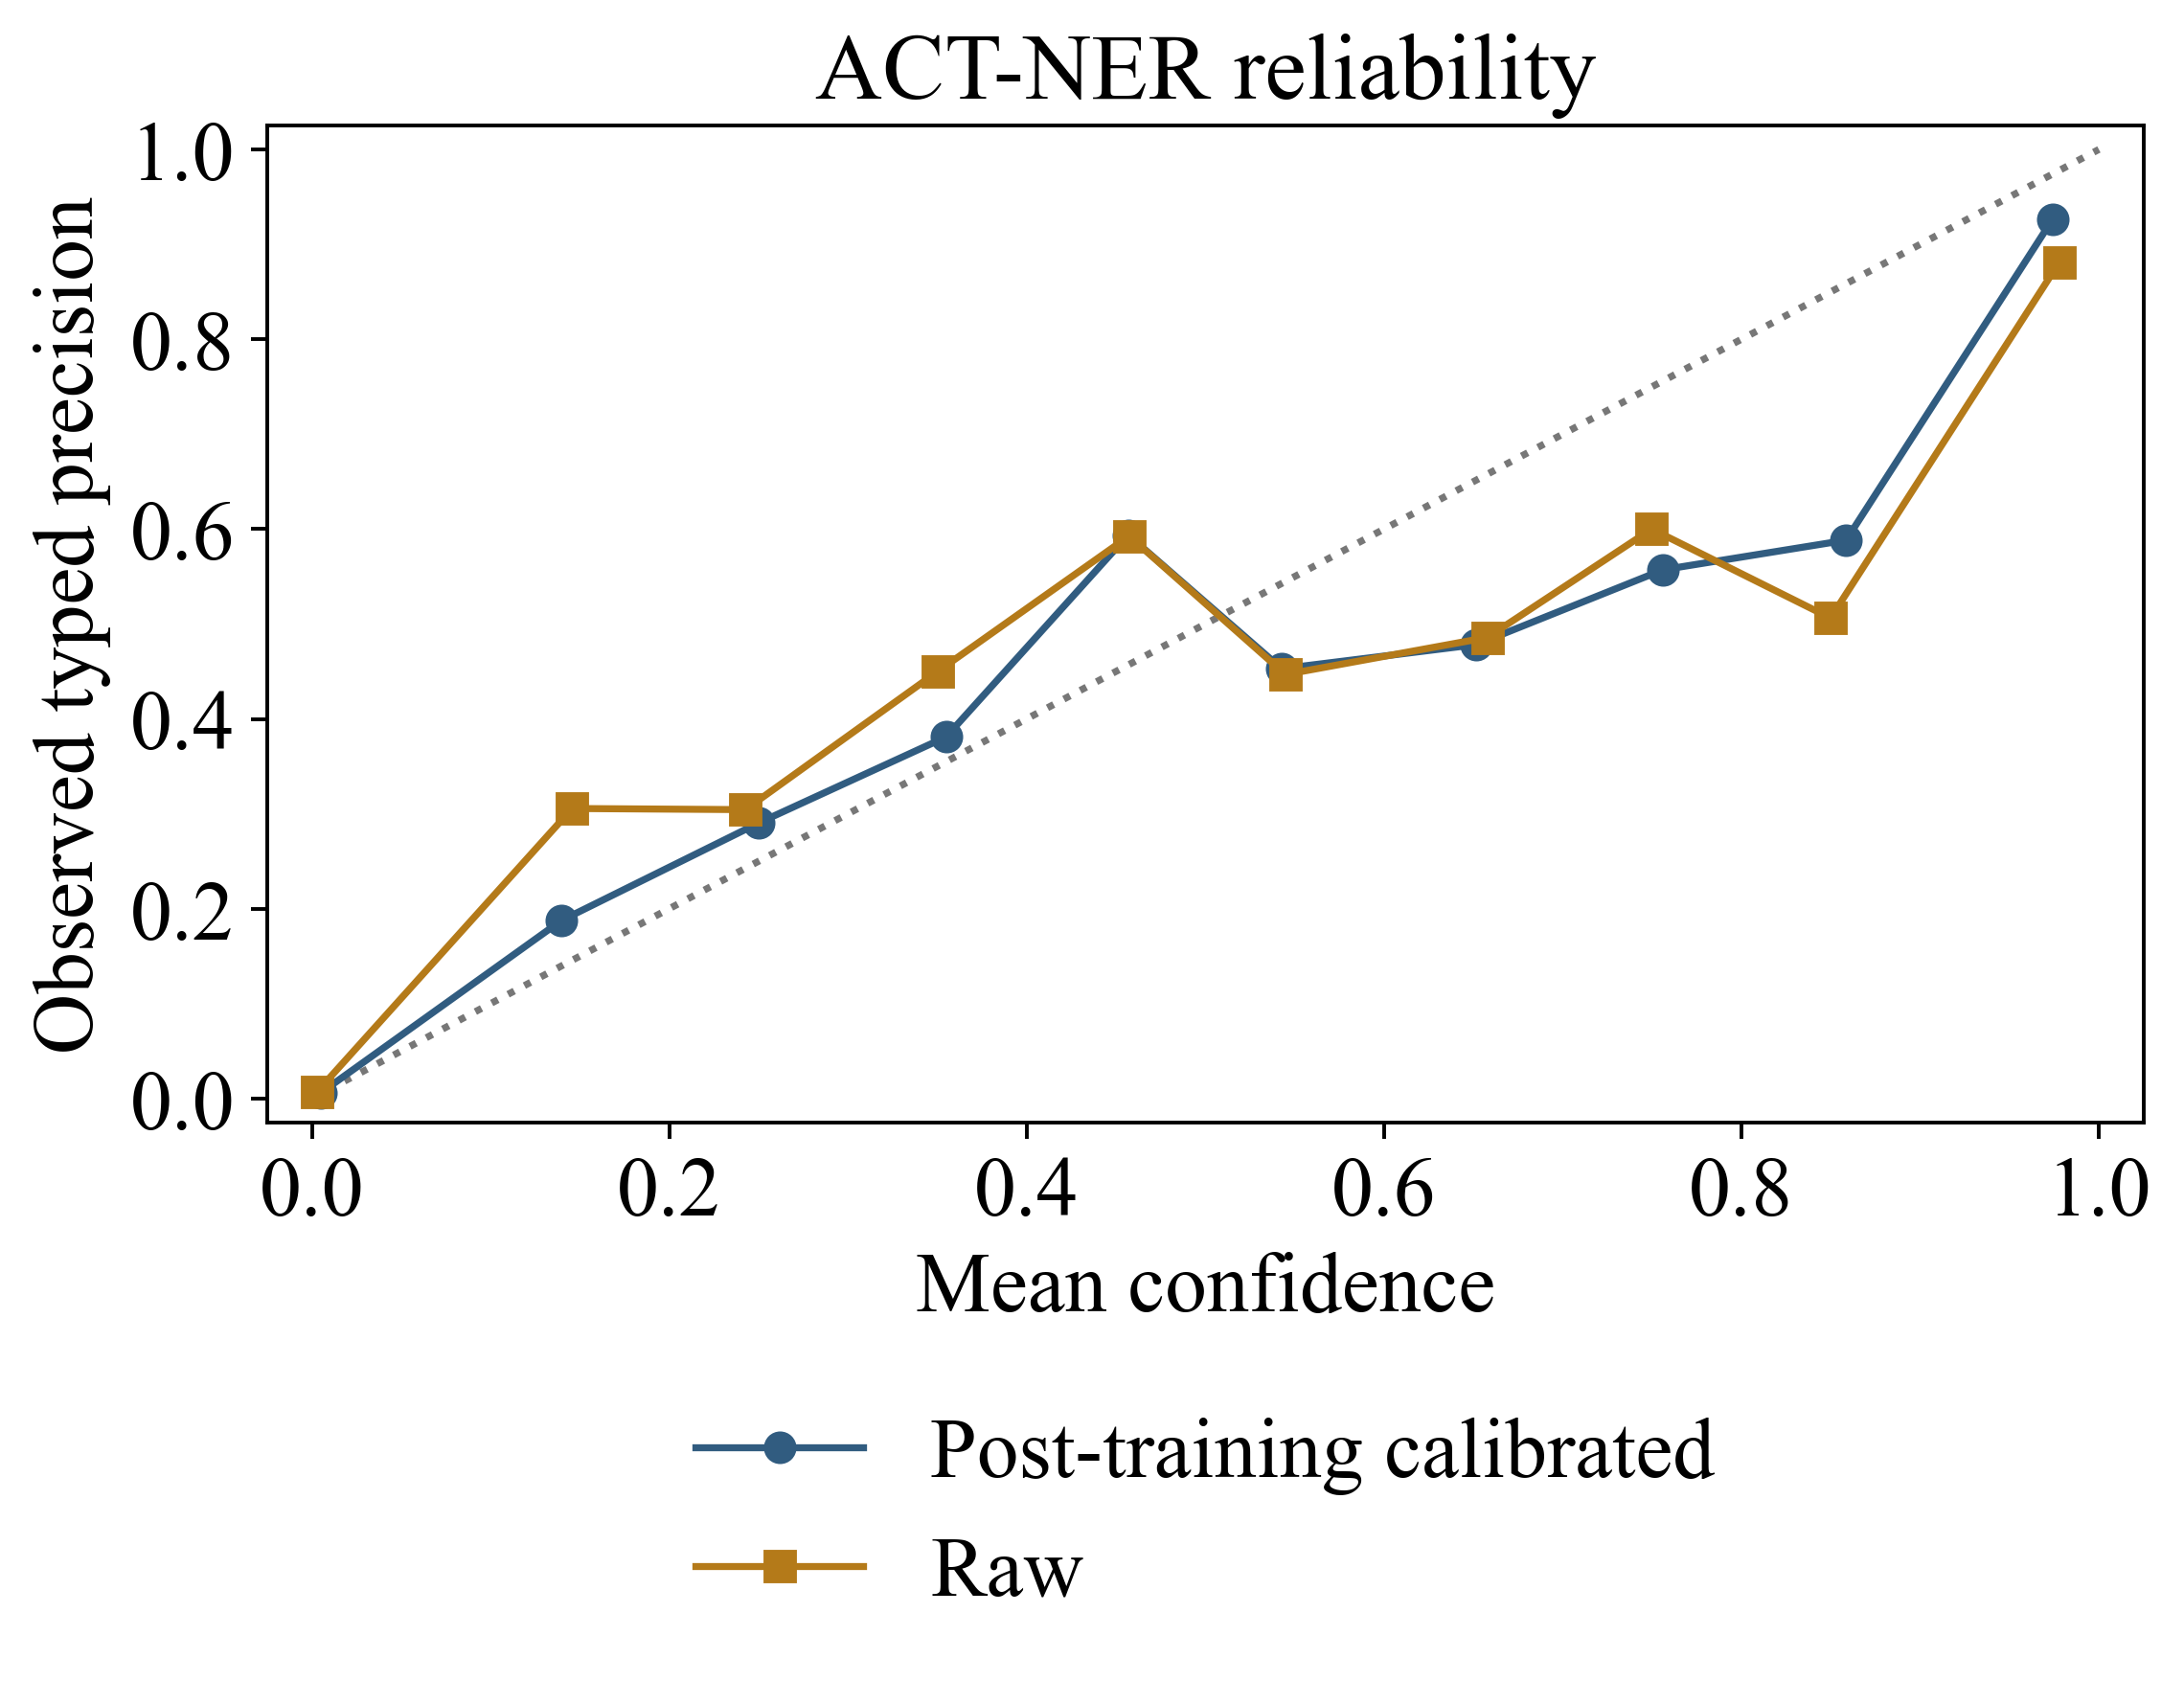

In [26]:
plot_data=reliability.query("Model == 'ACT-NER'")
fig,ax=plt.subplots(figsize=(6.4,4.9),layout="constrained")
ax.plot([0,1],[0,1],color="#777777",linestyle=":")
for i,(policy,part) in enumerate(plot_data.groupby("Confidence",sort=True)):
    ax.plot(part["Mean confidence"],part["Observed precision"],marker=["o","s"][i],
        color=["#315C80","#B47A19"][i],label=policy)
ax.set(xlabel="Mean confidence",ylabel="Observed typed precision",title="ACT-NER reliability",
    xlim=(-.025,1.025),ylim=(-.025,1.025),xticks=np.linspace(0,1,6),yticks=np.linspace(0,1,6))
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=1,frameon=False)

mpl.rcParams["pdf.fonttype"]=42
fig.canvas.draw()
assert all(18<=label.get_fontsize()<=20 for label in fig.findobj(mpl.text.Text)
           if label.get_visible() and label.get_text().strip())
fig.savefig(PROJECT_ROOT/"figures/PNG/refinement_06_reliability.png",dpi=350,bbox_inches="tight",facecolor="white")
fig.savefig(PROJECT_ROOT/"figures/PDF/refinement_06_reliability.pdf",dpi=350,bbox_inches="tight",facecolor="white")
plot_data.to_csv(PROJECT_ROOT/"artifacts/refinement_06_reliability_source.csv",index=False)
plt.show()
plt.close(fig)

## Selective prediction

How does confidence ordering change error risk as emitted predictions are retained?

In [27]:
risk_summary,risk_curves=selective_prediction(predictions,entities)
risk_summary.to_csv(PROJECT_ROOT/"artifacts/refinement_06_risk.csv",index=False)
display(risk_summary.style.format(precision=4,na_rep="Not defined: no emitted entities").hide(axis="index"))

Model,Emitted entities,AURC,Coverage definition
ACT-NER,676,0.0934,Retained / emitted predictions
O-only,0,Not defined: no emitted entities,Retained / emitted predictions
Longest-match lexicon,683,0.2462,Retained / emitted predictions
Logistic Regression,2110,0.5662,Retained / emitted predictions
Linear-chain CRF,590,0.0964,Retained / emitted predictions
BiLSTM-CRF,599,0.1701,Retained / emitted predictions
Biomedical Transformer,797,0.1437,Retained / emitted predictions


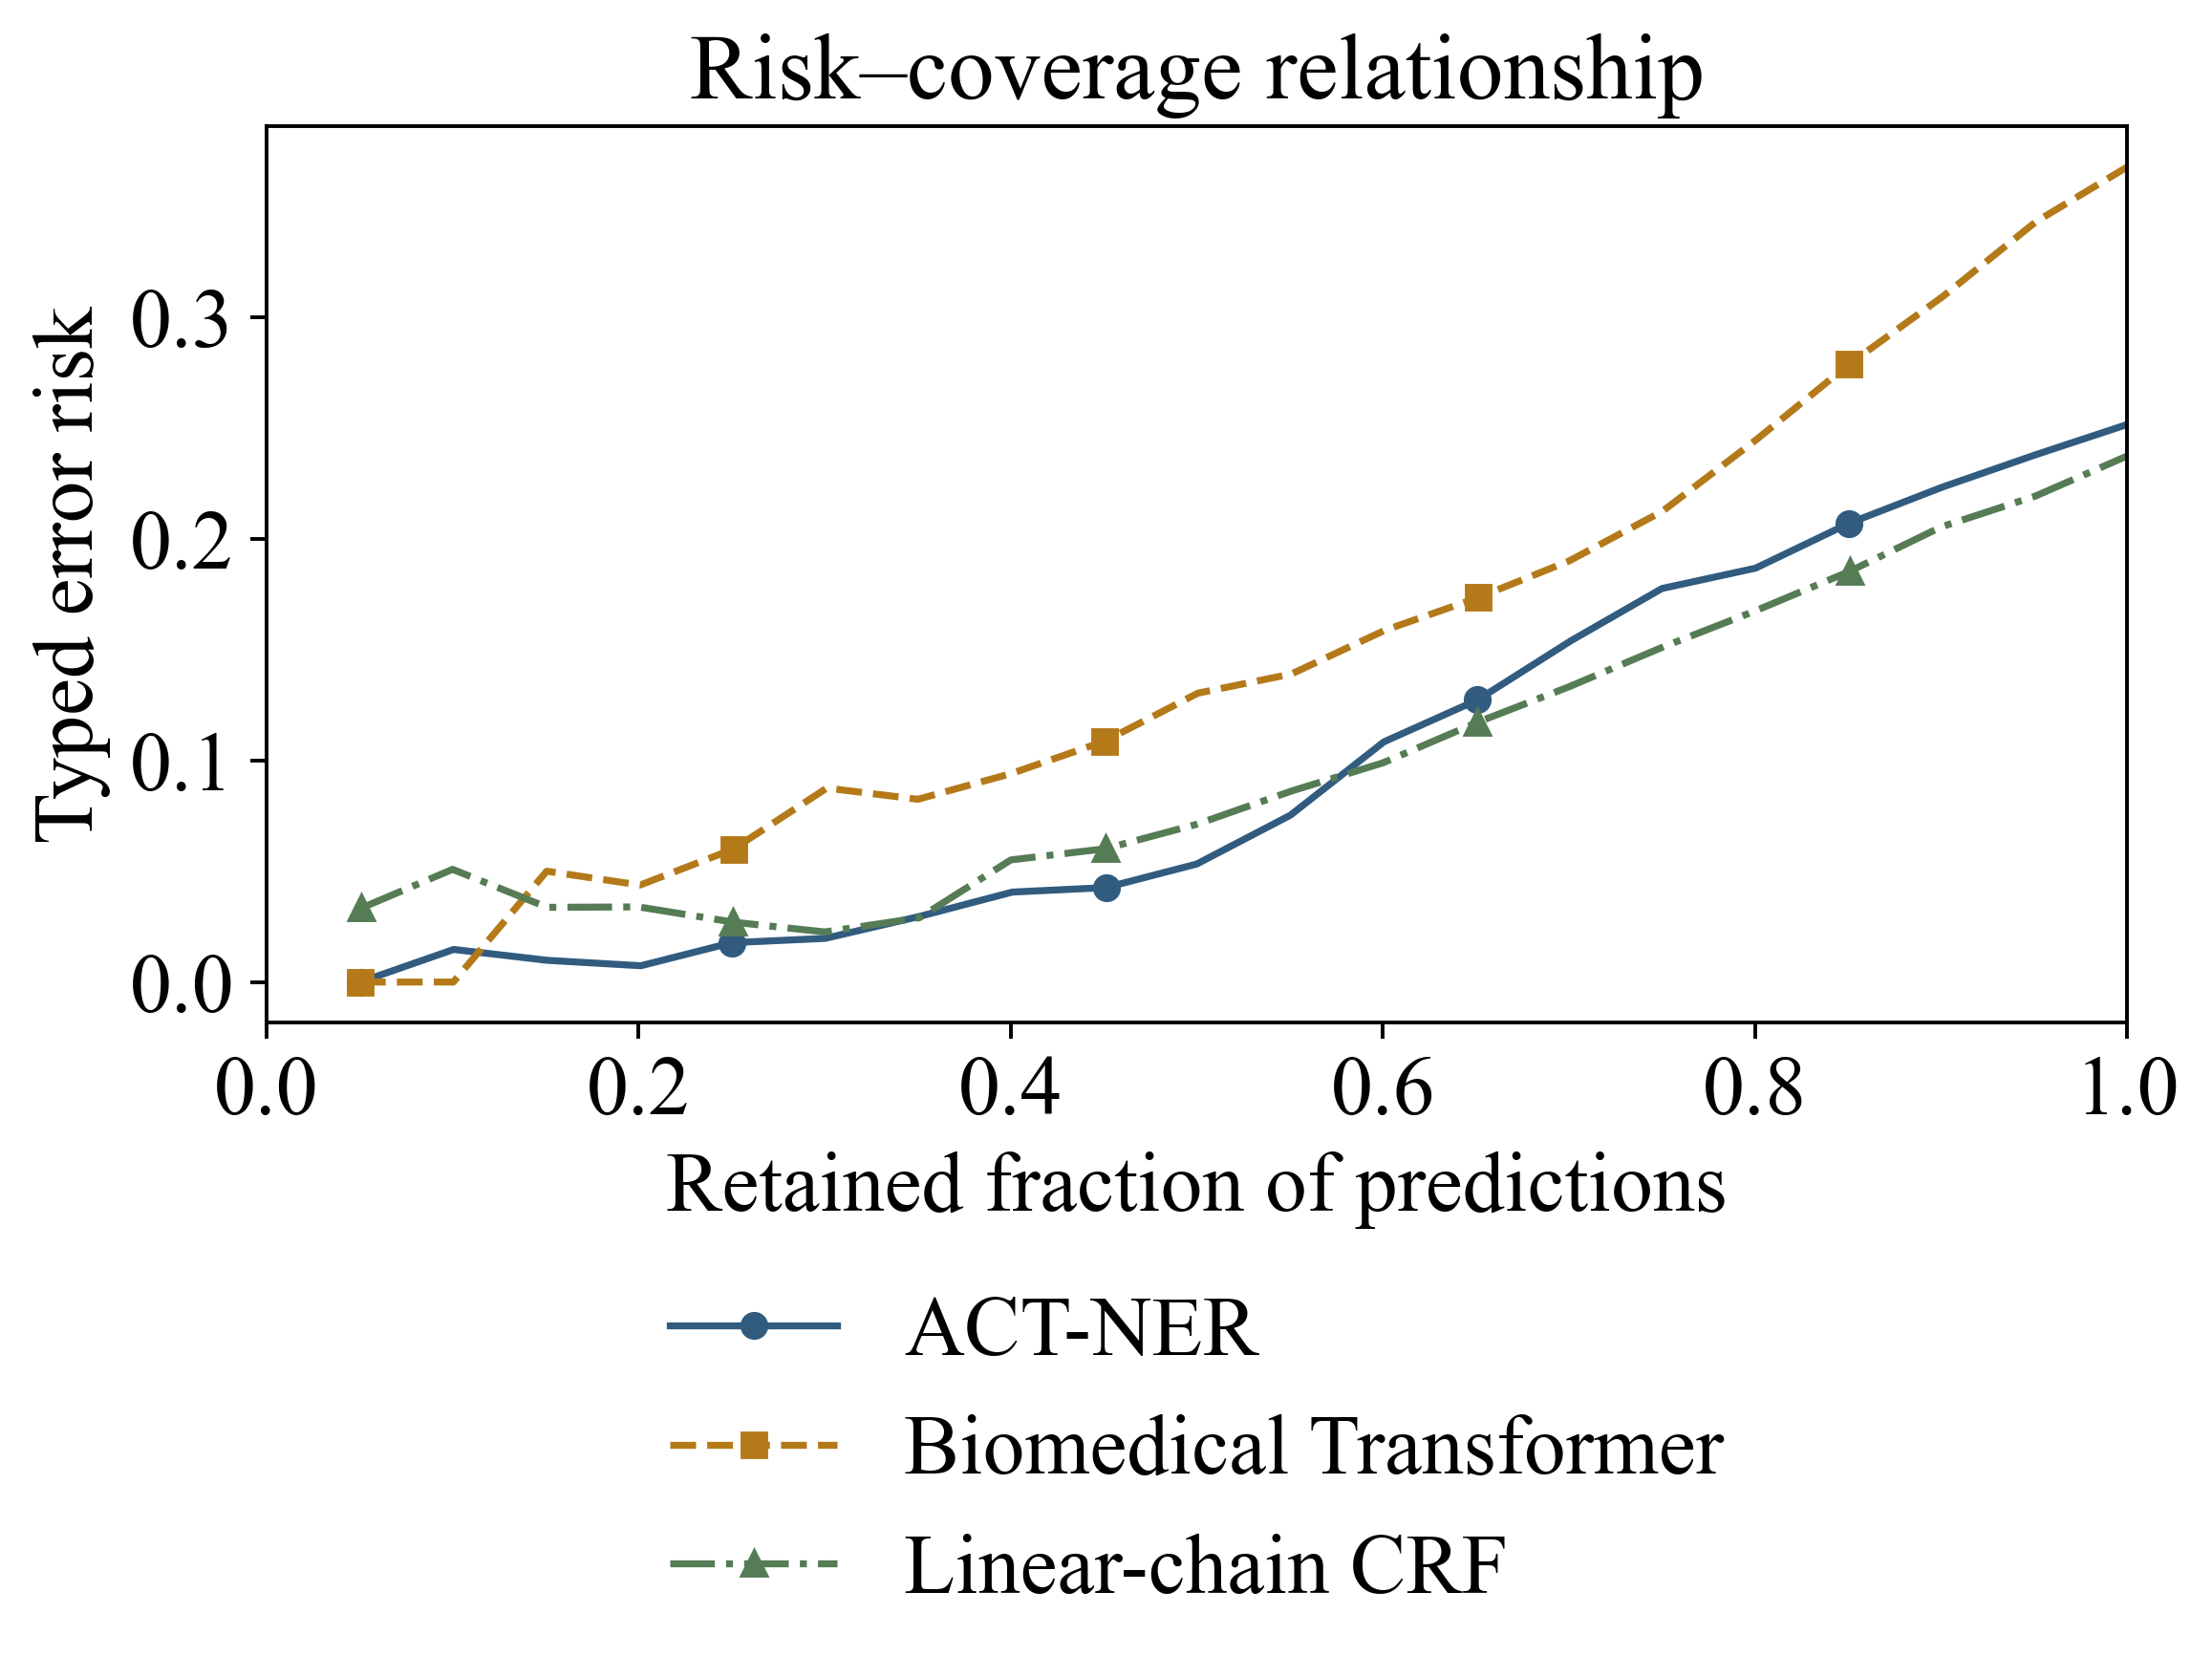

In [28]:
plot_data=risk_curves.query("Model in ['ACT-NER','Linear-chain CRF','Biomedical Transformer']")
fig,ax=plt.subplots(figsize=(6.5,4.9),layout="constrained")
for i,(name,part) in enumerate(plot_data.groupby("Model",sort=True)):
    ax.plot(part.Coverage,part.Risk,label=name,color=["#315C80","#B47A19","#557C55"][i],
        linestyle=["-","--","-."][i],marker=["o","s","^"][i],markevery=4,markersize=5)
ax.set(xlabel="Retained fraction of predictions",ylabel="Typed error risk",title="Risk–coverage relationship",xlim=(0,1))
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=1,frameon=False)

mpl.rcParams["pdf.fonttype"]=42
fig.canvas.draw()
assert all(18<=label.get_fontsize()<=20 for label in fig.findobj(mpl.text.Text)
           if label.get_visible() and label.get_text().strip())
fig.savefig(PROJECT_ROOT/"figures/PNG/refinement_06_risk_coverage.png",dpi=350,bbox_inches="tight",facecolor="white")
fig.savefig(PROJECT_ROOT/"figures/PDF/refinement_06_risk_coverage.pdf",dpi=350,bbox_inches="tight",facecolor="white")
plot_data.to_csv(PROJECT_ROOT/"artifacts/refinement_06_risk_coverage_source.csv",index=False)
plt.show()
plt.close(fig)

Coverage is relative to emitted predictions, not gold entities. Rejecting difficult predictions can reduce risk while reducing recall; the accompanying selective-F1 curve keeps the complete gold denominator.

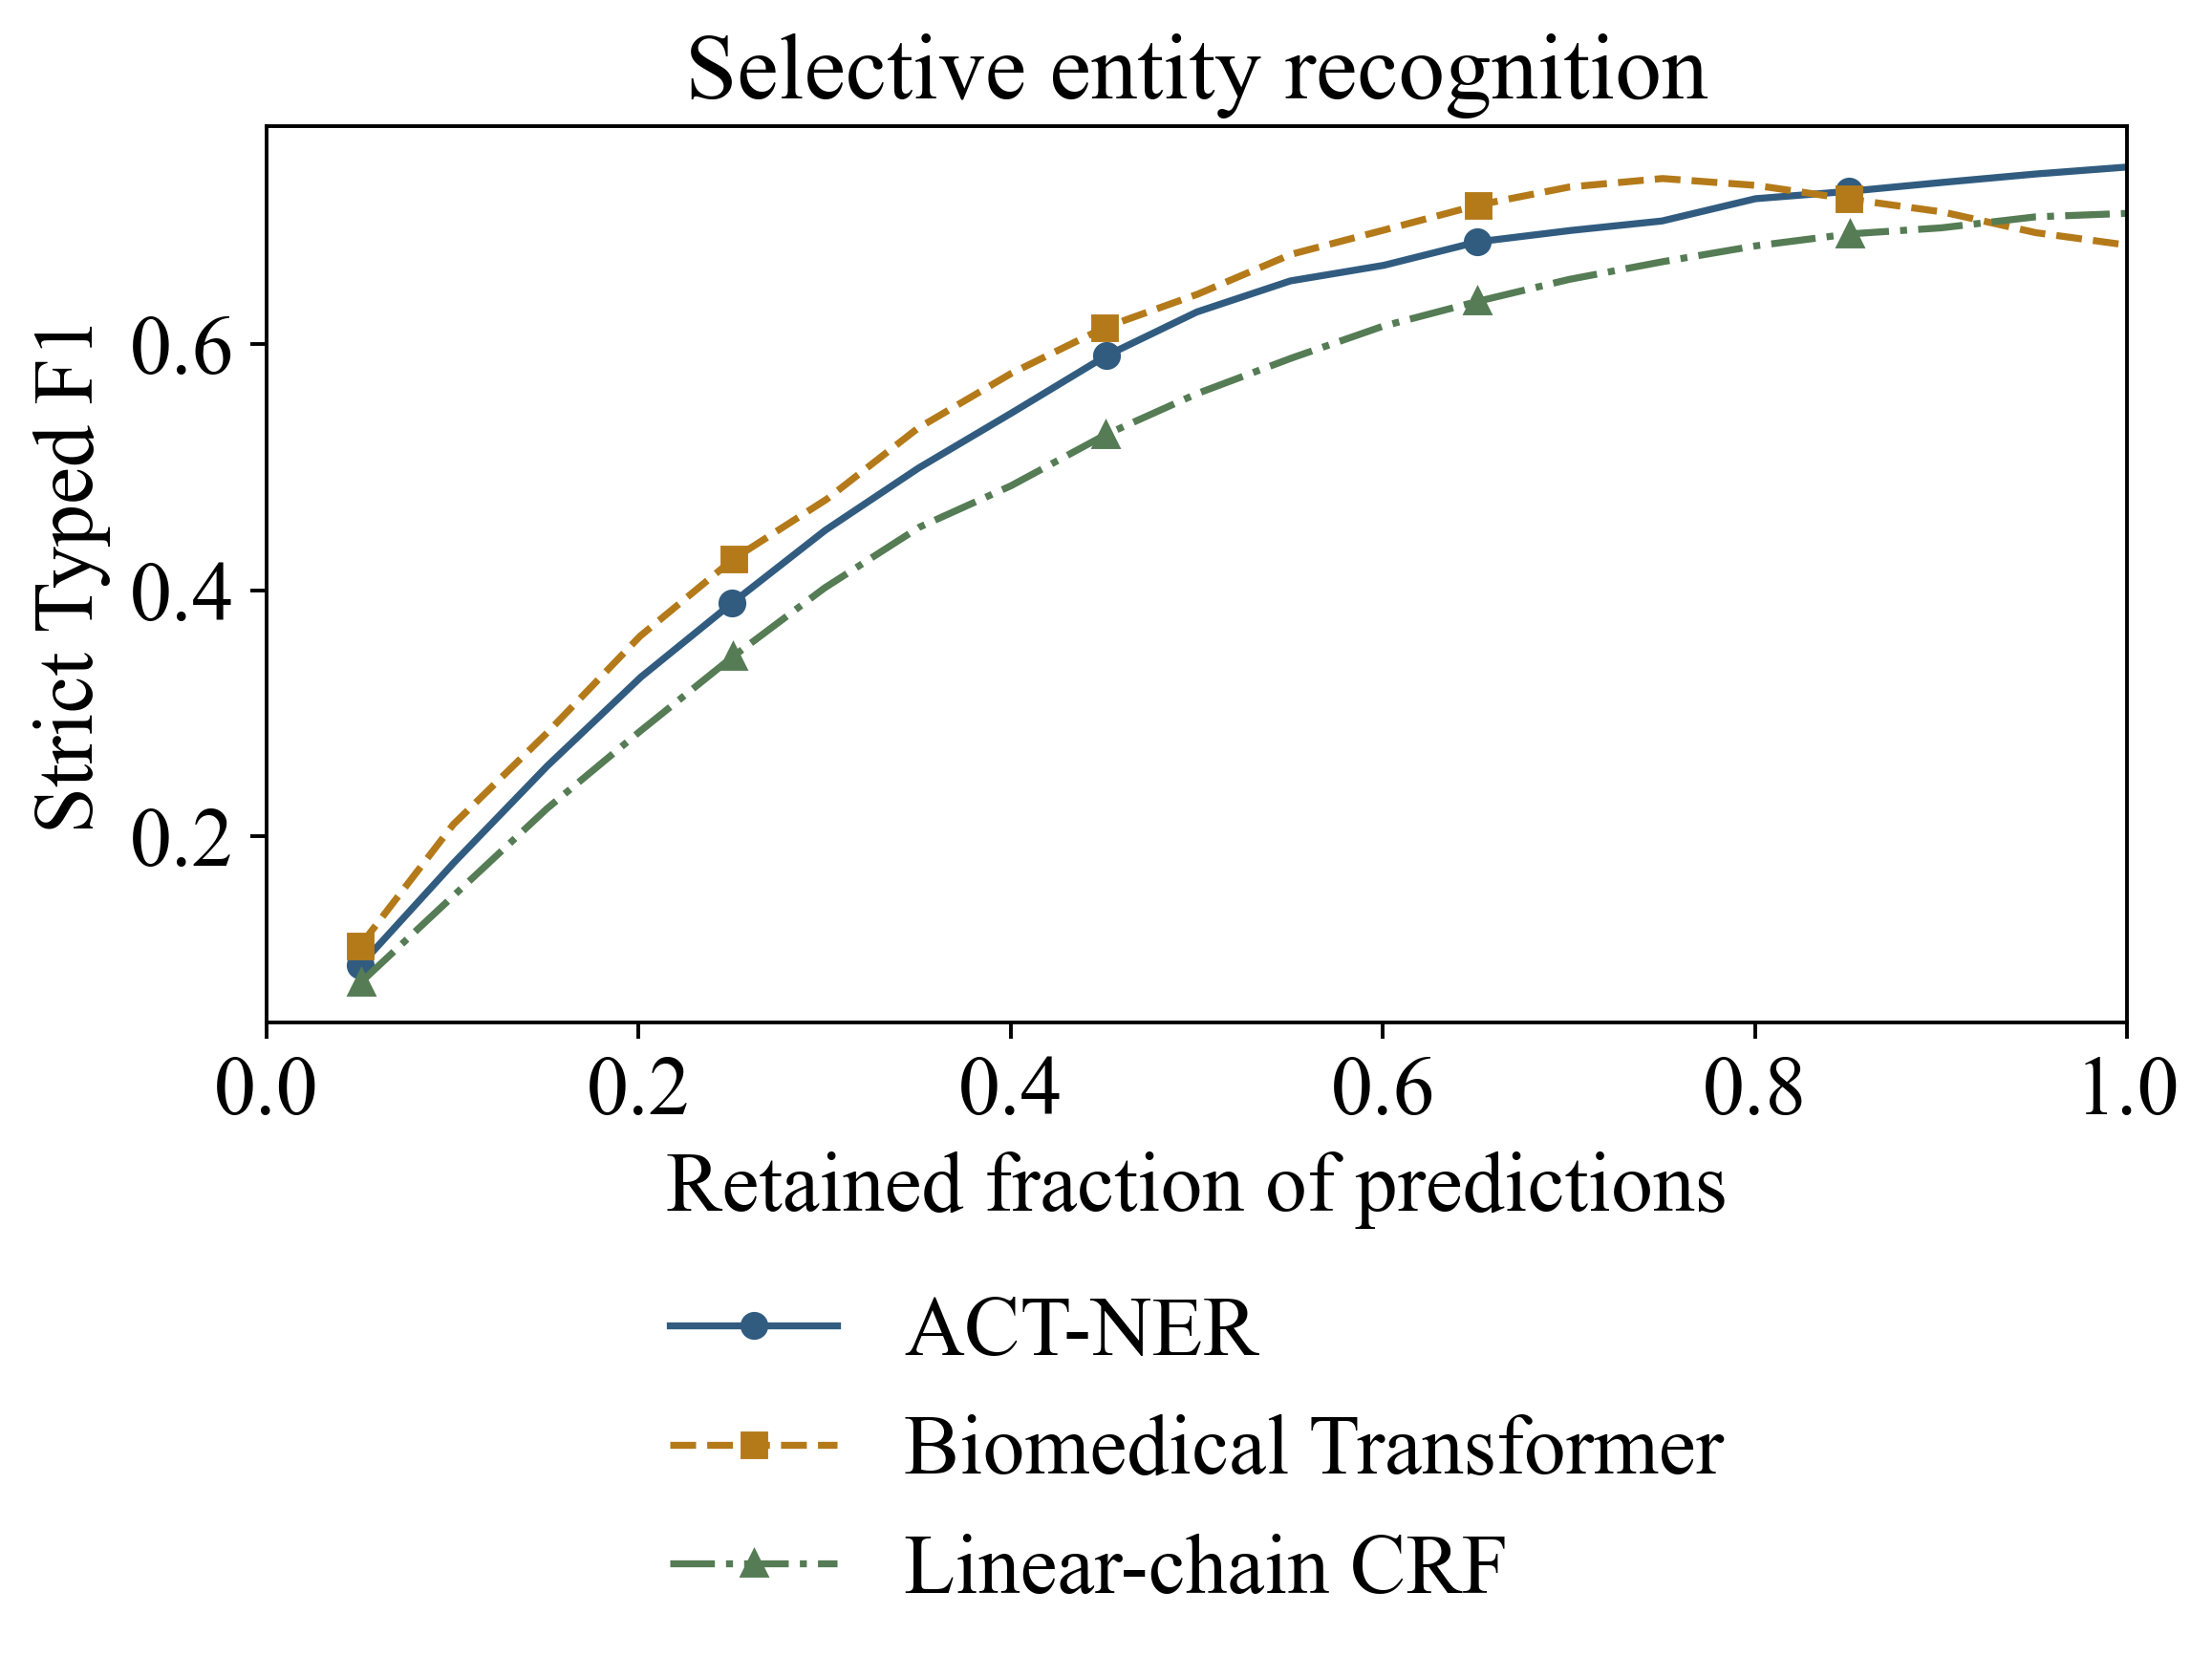

In [29]:
fig,ax=plt.subplots(figsize=(6.5,4.9),layout="constrained")
for i,(name,part) in enumerate(plot_data.groupby("Model",sort=True)):
    ax.plot(part.Coverage,part["Typed F1"],label=name,color=["#315C80","#B47A19","#557C55"][i],
        linestyle=["-","--","-."][i],marker=["o","s","^"][i],markevery=4,markersize=5)
ax.set(xlabel="Retained fraction of predictions",ylabel="Strict Typed F1",title="Selective entity recognition",xlim=(0,1))
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=1,frameon=False)

mpl.rcParams["pdf.fonttype"]=42
fig.canvas.draw()
assert all(18<=label.get_fontsize()<=20 for label in fig.findobj(mpl.text.Text)
           if label.get_visible() and label.get_text().strip())
fig.savefig(PROJECT_ROOT/"figures/PNG/refinement_06_selective_f1.png",dpi=350,bbox_inches="tight",facecolor="white")
fig.savefig(PROJECT_ROOT/"figures/PDF/refinement_06_selective_f1.pdf",dpi=350,bbox_inches="tight",facecolor="white")
plot_data.to_csv(PROJECT_ROOT/"artifacts/refinement_06_selective_f1_source.csv",index=False)
plt.show()
plt.close(fig)

## Type errors conditional on exact boundaries

Which subtype substitutions remain after correct boundary recognition?

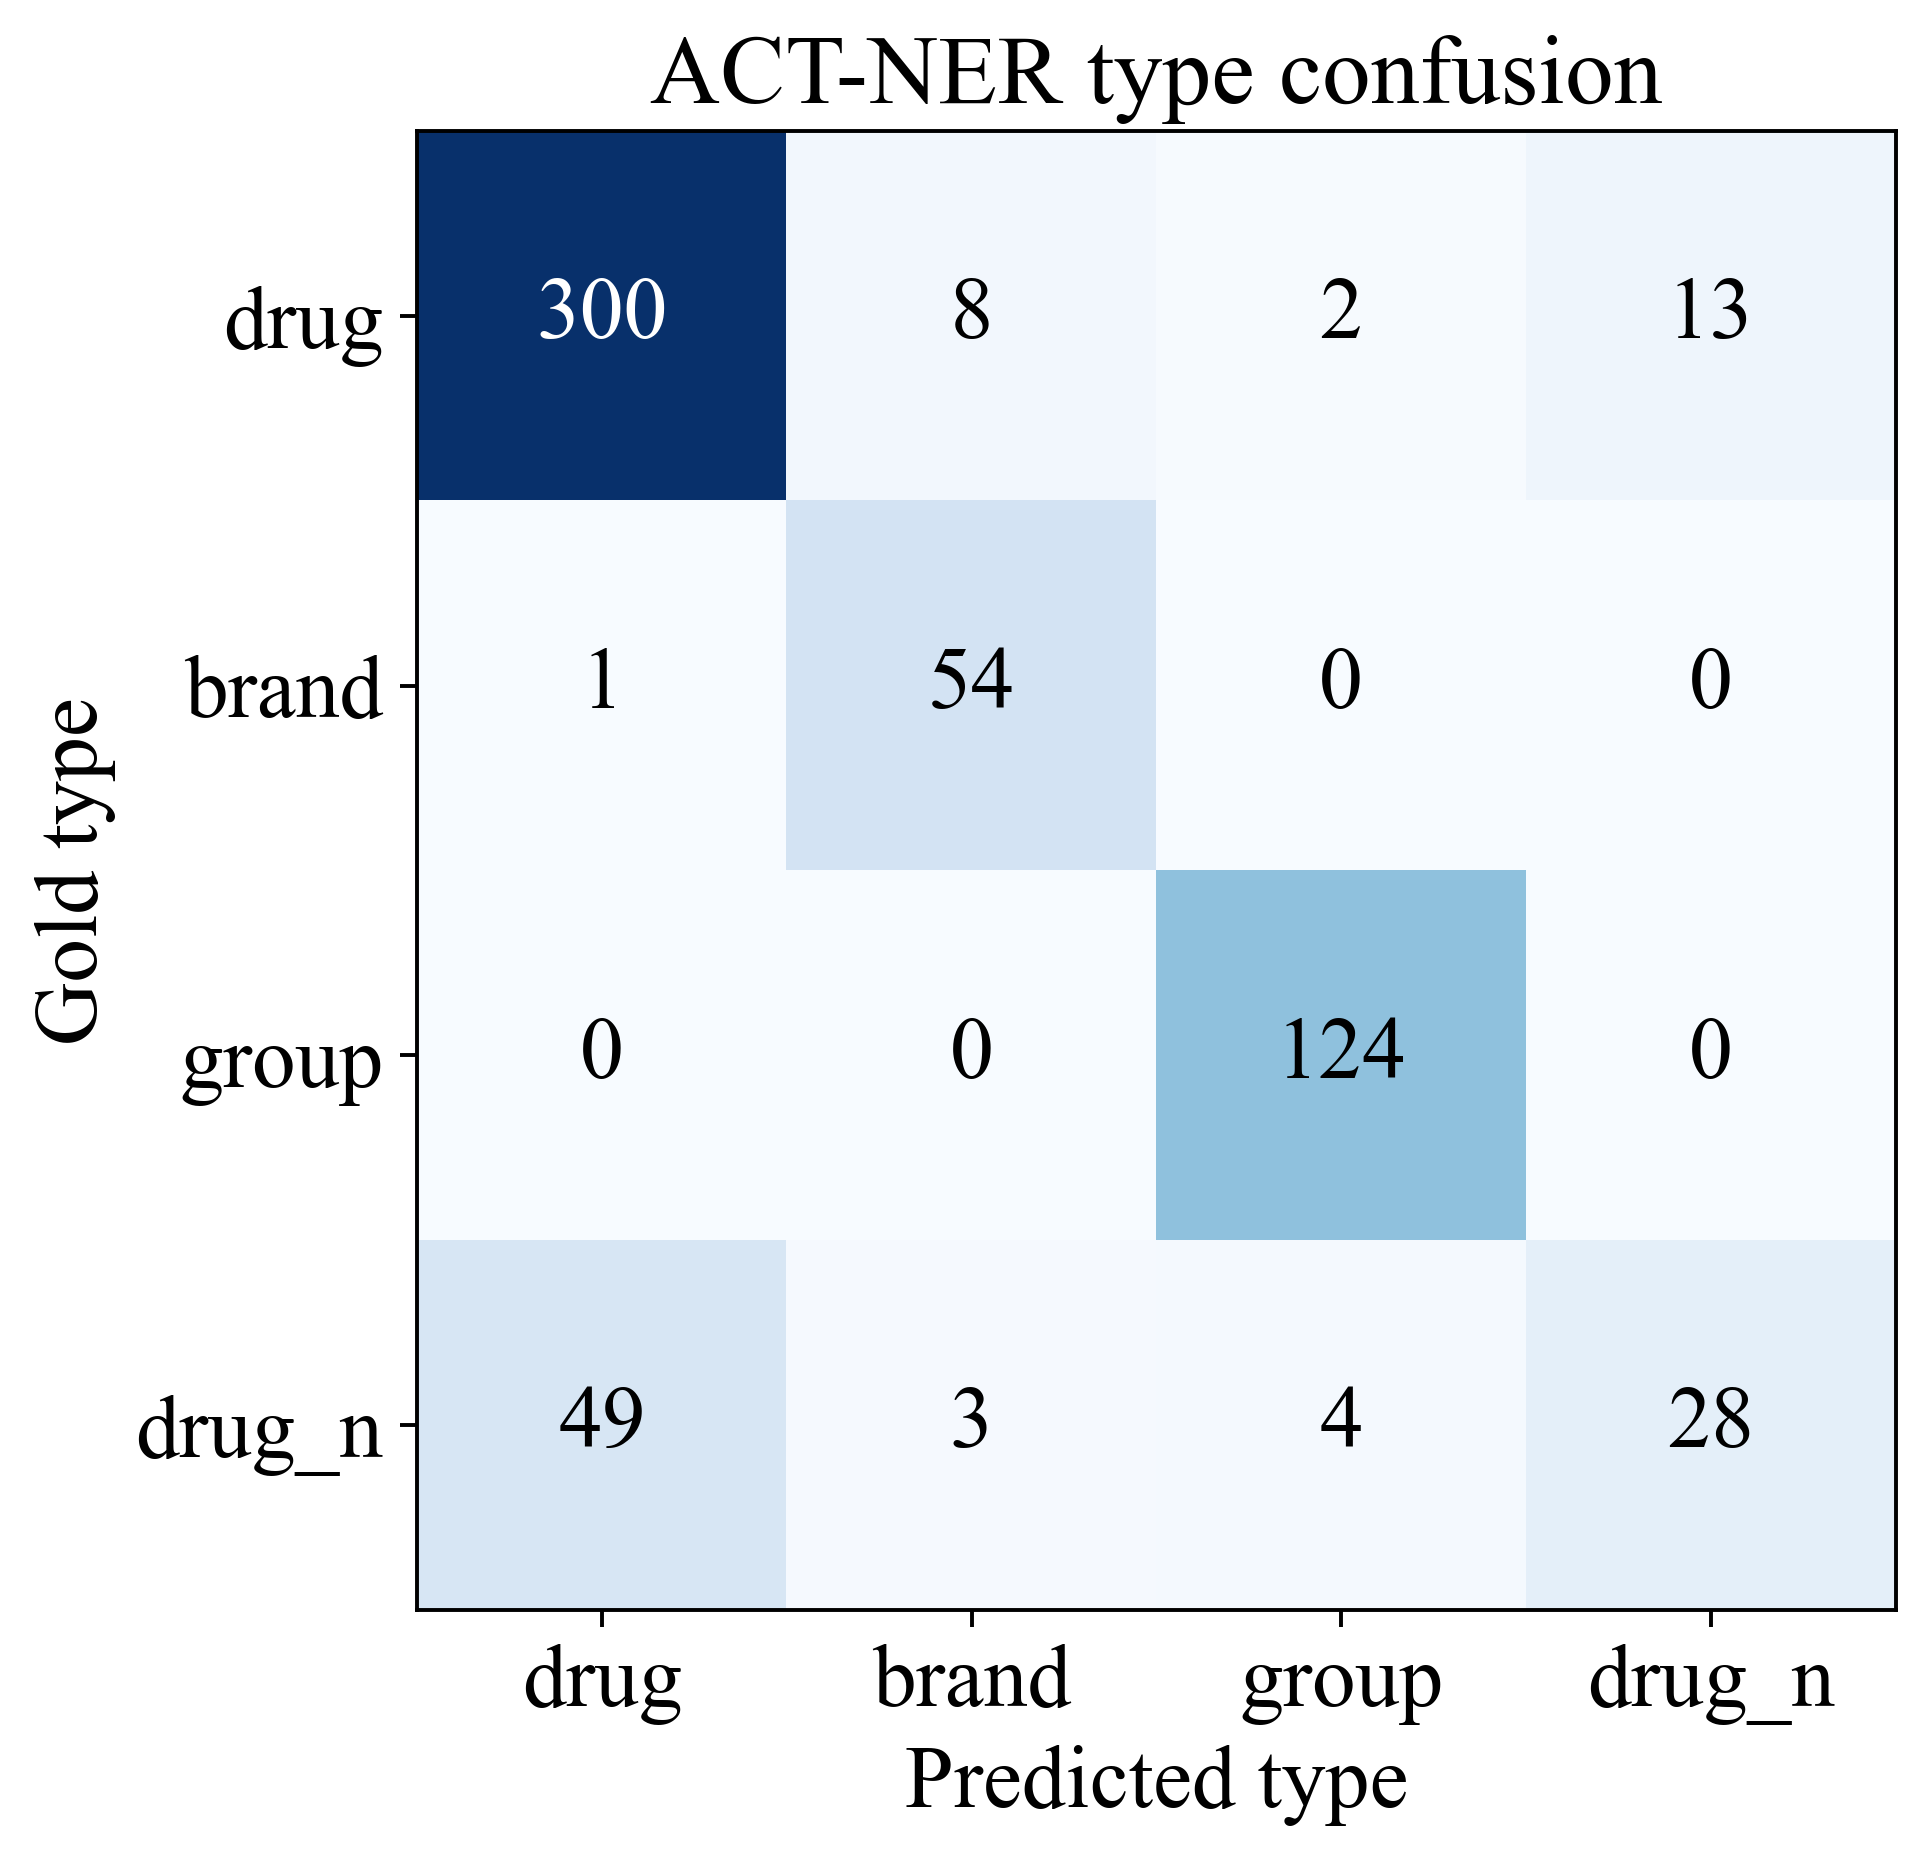

The matrix includes **586** exact-boundary matches out of **684** gold entities. Missed and spurious boundaries are excluded here and remain included in strict F1.

In [30]:
matrix,matched_count,gold_count=exact_type_confusion(predictions["ACT-NER"][17],entities)
fig,ax=plt.subplots(figsize=(5.7,5.2),layout="constrained")
values=matrix.to_numpy()
normalizer=mpl.colors.Normalize(vmin=0,vmax=max(1,values.max()))
ax.imshow(values,cmap="Blues",norm=normalizer,aspect="equal")
for i in range(4):
    for j in range(4):
        rgba=mpl.colormaps["Blues"](normalizer(values[i,j]))
        luminance=.2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
        ax.text(j,i,str(values[i,j]),ha="center",va="center",color="white" if luminance<.5 else "black")
ax.set(xticks=range(4),xticklabels=matrix.columns,yticks=range(4),yticklabels=matrix.index,
    xlabel="Predicted type",ylabel="Gold type",title="ACT-NER type confusion")
plot_data=matrix.reset_index()

mpl.rcParams["pdf.fonttype"]=42
fig.canvas.draw()
assert all(18<=label.get_fontsize()<=20 for label in fig.findobj(mpl.text.Text)
           if label.get_visible() and label.get_text().strip())
fig.savefig(PROJECT_ROOT/"figures/PNG/refinement_06_type_confusion.png",dpi=350,bbox_inches="tight",facecolor="white")
fig.savefig(PROJECT_ROOT/"figures/PDF/refinement_06_type_confusion.pdf",dpi=350,bbox_inches="tight",facecolor="white")
plot_data.to_csv(PROJECT_ROOT/"artifacts/refinement_06_type_confusion_source.csv",index=False)
plt.show()
plt.close(fig)

display(Markdown(f"The matrix includes **{matched_count:,}** exact-boundary matches out of **{gold_count:,}** gold entities. "
    "Missed and spurious boundaries are excluded here and remain included in strict F1."))

## Error mechanisms

Which kinds of emitted-entity errors remain after frozen decoding?

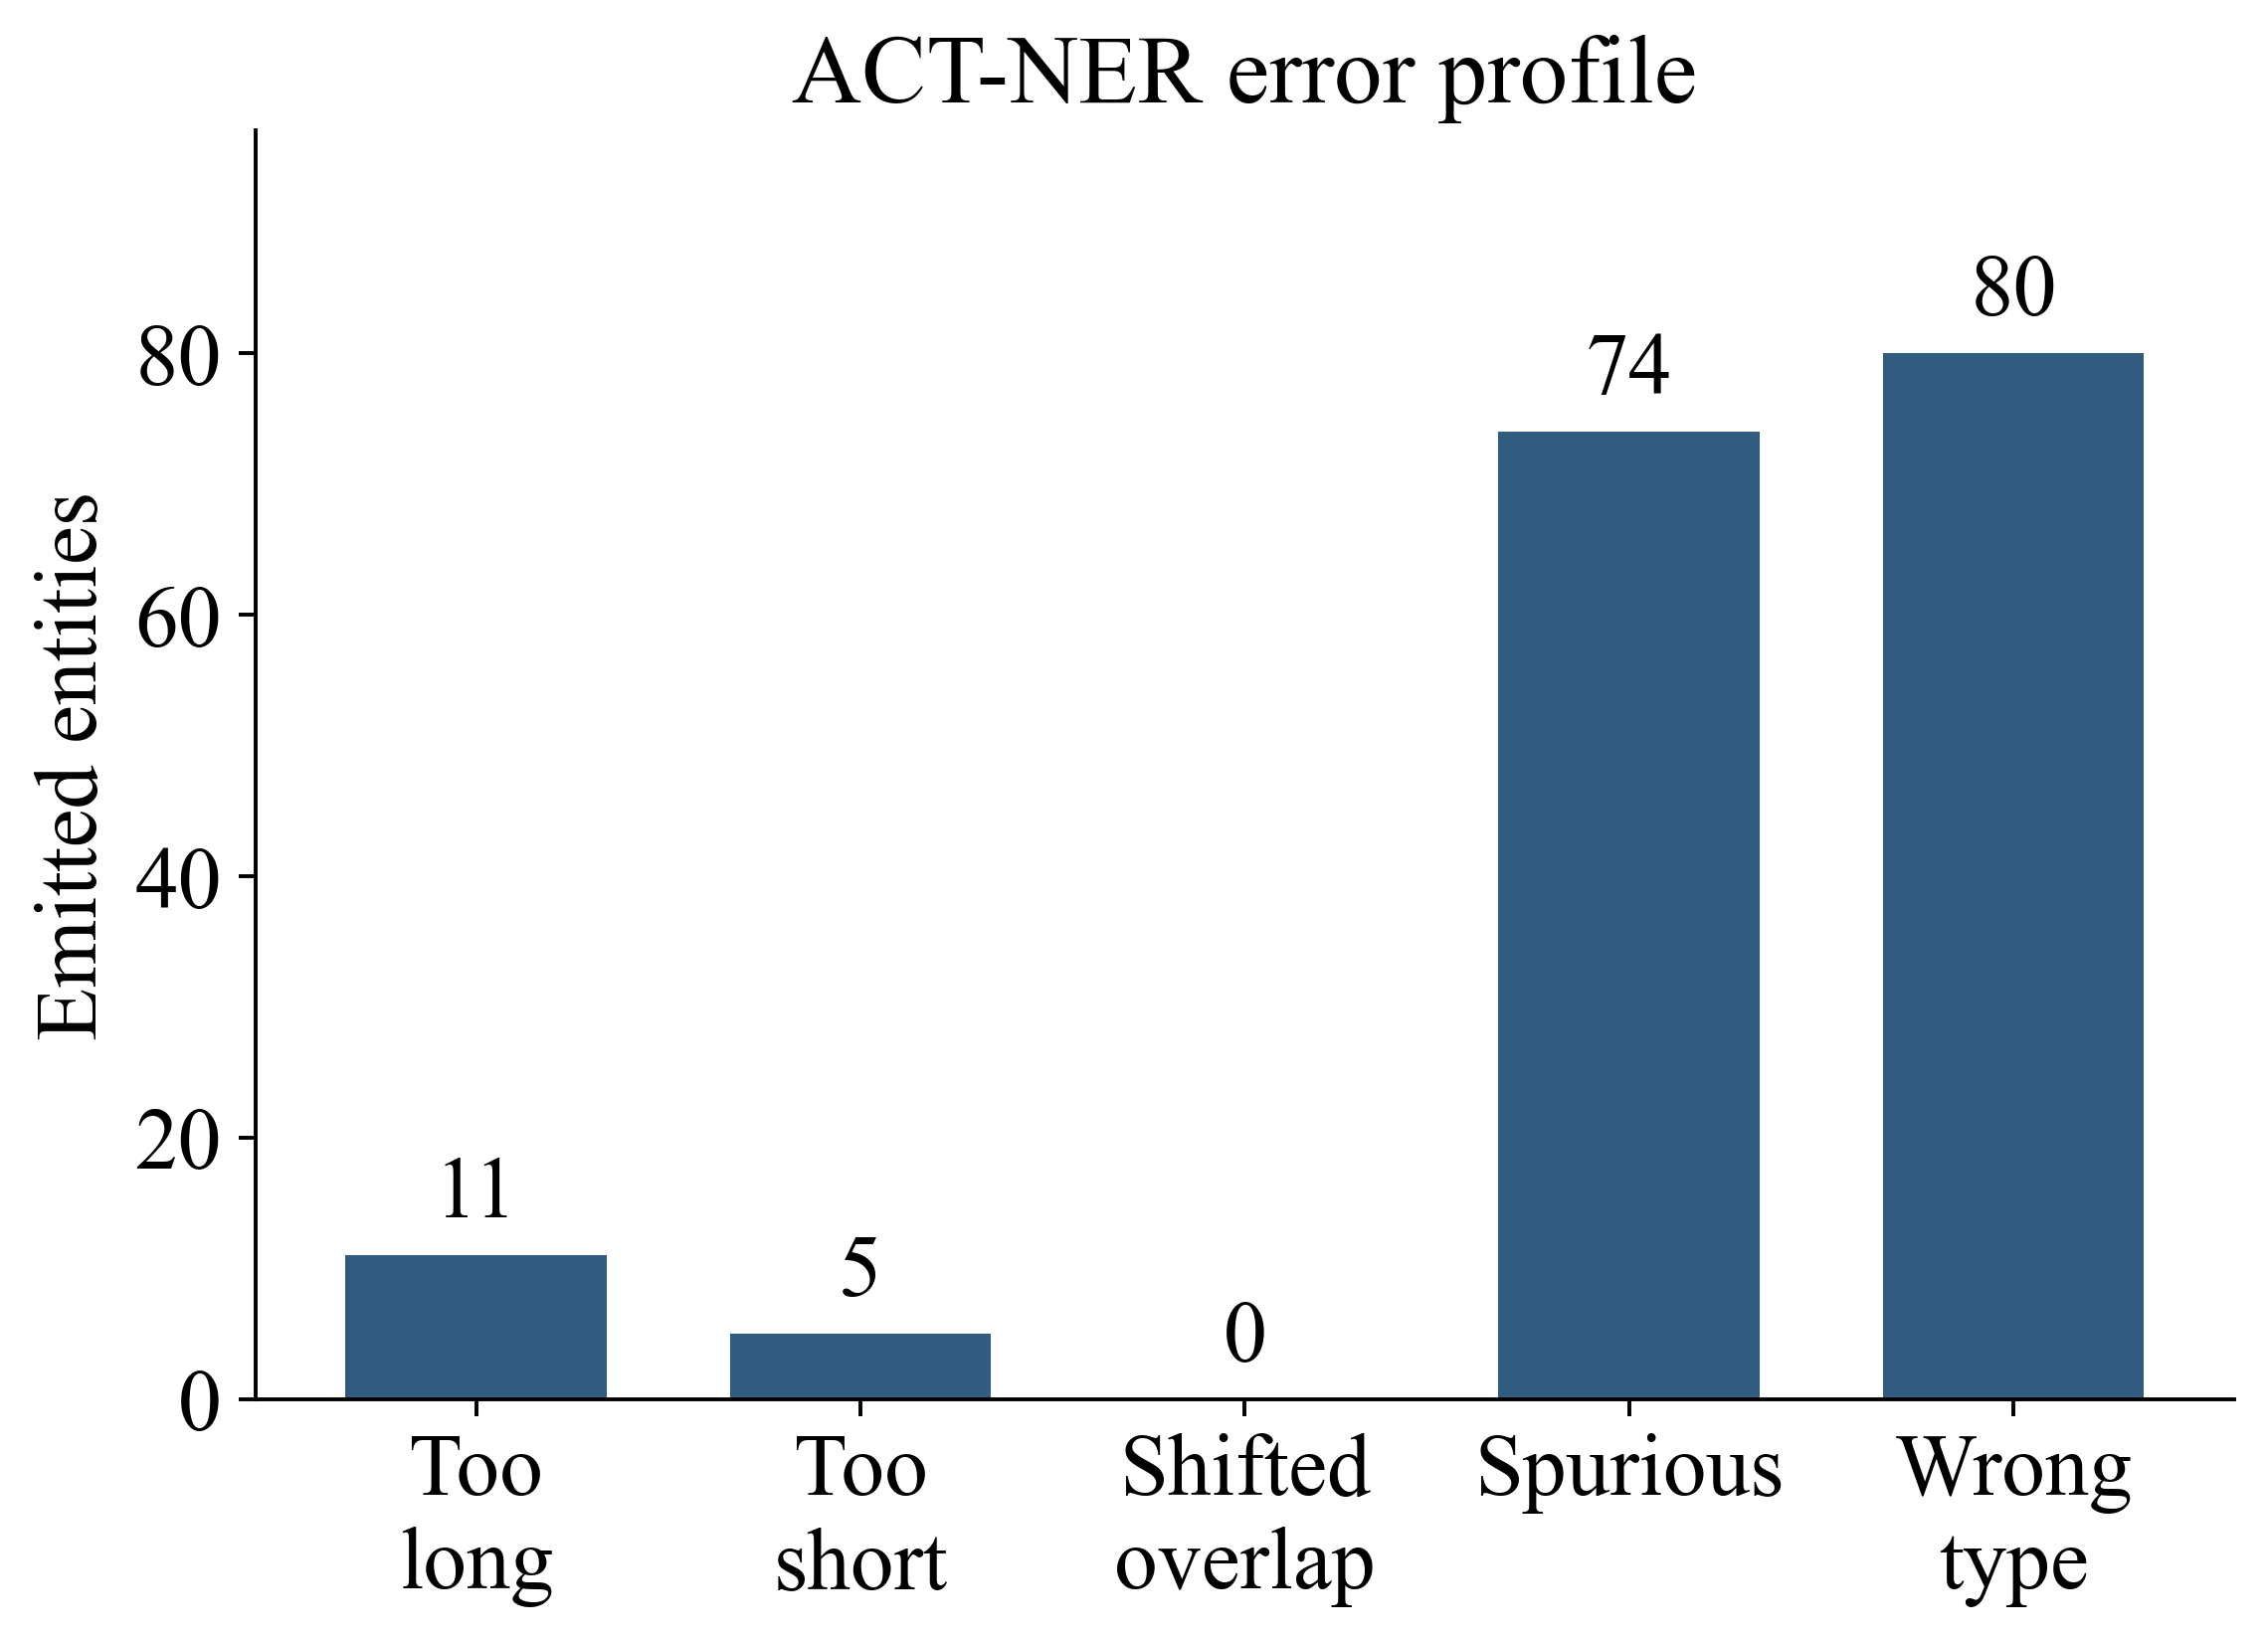

The largest emitted-error category is **Wrong type (80)**. A further **98** gold entities lack an exact-boundary prediction. These are different denominators; errors characterize the frozen system and do not trigger test-driven adjustment.

In [31]:
taxonomy=boundary_taxonomy(predictions["ACT-NER"][17],entities)
categories=["Too long","Too short","Shifted overlap","Spurious","Wrong type"]
plot_data=taxonomy.set_index("Error").reindex(categories).reset_index()
plot_data["Entities"]=plot_data.Entities.fillna(0).astype(int)
fig,ax=plt.subplots(figsize=(6.4,4.6),layout="constrained")
bars=ax.bar(range(len(plot_data)),plot_data.Entities,color="#315C80",width=.68)
ax.bar_label(bars,padding=4,fontsize=18)
ax.set(xticks=range(len(plot_data)),xticklabels=["Too\nlong","Too\nshort","Shifted\noverlap","Spurious","Wrong\ntype"],
    ylabel="Emitted entities",title="ACT-NER error profile",ylim=(0,max(1,plot_data.Entities.max())*1.20+1))
ax.spines[["top","right"]].set_visible(False)

mpl.rcParams["pdf.fonttype"]=42
fig.canvas.draw()
assert all(18<=label.get_fontsize()<=20 for label in fig.findobj(mpl.text.Text)
           if label.get_visible() and label.get_text().strip())
fig.savefig(PROJECT_ROOT/"figures/PNG/refinement_06_error_profile.png",dpi=350,bbox_inches="tight",facecolor="white")
fig.savefig(PROJECT_ROOT/"figures/PDF/refinement_06_error_profile.pdf",dpi=350,bbox_inches="tight",facecolor="white")
plot_data.to_csv(PROJECT_ROOT/"artifacts/refinement_06_error_profile_source.csv",index=False)
plt.show()
plt.close(fig)

largest=plot_data.loc[plot_data.Entities.idxmax()]
display(Markdown(f"The largest emitted-error category is **{largest.Error} ({largest.Entities:,})**. "
    f"A further **{gold_count-matched_count:,}** gold entities lack an exact-boundary prediction. "
    "These are different denominators; errors characterize the frozen system and do not trigger test-driven adjustment."))

## Observed inference cost

What is the measured cost of the complete frozen prediction pipeline on this device?

In [32]:
efficiency_table=pd.DataFrame([efficiency])
efficiency_table.to_csv(PROJECT_ROOT/"artifacts/refinement_06_efficiency.csv",index=False)
display(efficiency_table[["Model","Sentences","Entities","End-to-end seconds","Milliseconds per sentence","Sentences per second"]].style.format(precision=3).hide(axis="index"))
display(efficiency_table[["Model","Trainable parameters","Head MiB","Expert seconds","Head seconds","Milliseconds per entity"]].style.format(precision=3,na_rep="Not defined: no emitted entities").hide(axis="index"))

Model,Sentences,Entities,End-to-end seconds,Milliseconds per sentence,Sentences per second
ACT-NER,665,676,8.288,12.463,80.237


Model,Trainable parameters,Head MiB,Expert seconds,Head seconds,Milliseconds per entity
ACT-NER,363291,1.399,3.515,0.896,12.260


The end-to-end measurement includes checkpoint loading, frozen expert inference, candidate features and decoding. It is a single-device batch measurement, not a clinical deployment benchmark. Head size excludes frozen expert files.

## Additional reserved same-corpus holdout

Does the frozen model generalize to the 191 separately reserved DDIExtraction documents? Prior recorded access concerned root IDs only. These data are not an external corpus; unrecorded prior exposure cannot be ruled out. The eligibility and duplicate-exclusion policy was sealed before the final checkpoint.

In [33]:
from refinement_holdout import additional_population,additional_inference
hold_documents,hold_sentences,hold_entities,hold_tokens=additional_population(PROJECT_ROOT)
population=hold_documents.groupby(["source","eligible_independent_text"]).size().rename("Documents").reset_index()
population.to_csv(PROJECT_ROOT/"artifacts/refinement_06_additional_population.csv",index=False)
display(population)

,source,eligible_independent_text,Documents
0,DrugBank,False,15
1,DrugBank,True,143
2,MedLine,True,33


In [34]:
with contextlib.redirect_stdout(io.StringIO()),contextlib.redirect_stderr(io.StringIO()):
    hold_predictions,hold_scores=additional_inference(PROJECT_ROOT,hold_sentences,hold_entities,hold_tokens)
eligible=set(hold_documents.loc[hold_documents.eligible_independent_text,"document_id"])
evaluation_sentences=hold_sentences.loc[hold_sentences.document_id.isin(eligible)]
evaluation_entities=hold_entities.loc[hold_entities.document_id.isin(eligible)]
evaluation_documents=hold_documents.loc[hold_documents.document_id.isin(eligible)].copy()
evaluation_documents["dependency_group"]=evaluation_documents.document_id.map(dependency_components(evaluation_sentences))
evaluation_predictions={name:{seed:frame.loc[frame.document_id.isin(eligible)].copy() for seed,frame in repeats.items()}
                       for name,repeats in hold_predictions.items()}
hold_quality=pd.DataFrame([{"Model":name,"Population":population,**strict_metrics(gold_frame,next(iter(repeats.values())))}
    for population,gold_frame,predict in [("All reserved documents",hold_entities,hold_predictions),
        ("Text-disjoint reserved documents",evaluation_entities,evaluation_predictions)]
    for name,repeats in predict.items()])
hold_quality.to_csv(PROJECT_ROOT/"artifacts/refinement_06_additional_quality.csv",index=False)
display(hold_quality[["Model","Population","N","boundary_f1","typed_precision","typed_recall","typed_f1","macro_f1"]].style.format(precision=4).hide(axis="index"))

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

Model,Population,N,boundary_f1,typed_precision,typed_recall,typed_f1,macro_f1
ACT-NER,All reserved documents,3031,0.9513,0.9087,0.9027,0.9057,0.8050
Biomedical Transformer,All reserved documents,3031,0.9146,0.8353,0.8888,0.8613,0.7291
Linear-chain CRF,All reserved documents,3031,0.8891,0.8887,0.8406,0.8640,0.6844
ACT-NER,Text-disjoint reserved documents,2717,0.9481,0.9024,0.8955,0.8989,0.8000
Biomedical Transformer,Text-disjoint reserved documents,2717,0.9078,0.8236,0.8800,0.8509,0.7204
Linear-chain CRF,Text-disjoint reserved documents,2717,0.8796,0.8799,0.8278,0.8530,0.6752


In [35]:
hold_evidence=paired_evidence(evaluation_predictions,evaluation_sentences,evaluation_entities,evaluation_documents,
    [("ACT-NER","Linear-chain CRF"),("ACT-NER","Biomedical Transformer")])
hold_evidence.to_csv(PROJECT_ROOT/"artifacts/refinement_06_additional_statistics.csv",index=False)
display(hold_evidence[["Comparison","N documents","Clusters","Micro-F1 difference","CI low","CI high","Micro-F1 Holm p"]].style.format(precision=5).hide(axis="index"))
_ = verify_evaluation_scope(PROJECT_ROOT)

Comparison,N documents,Clusters,Micro-F1 difference,CI low,CI high,Micro-F1 Holm p
ACT-NER − Linear-chain CRF,176,172,0.04592,0.02603,0.06784,0.00040
ACT-NER − Biomedical Transformer,176,172,0.04806,0.03270,0.06527,0.00040


Both the complete reserve and the prespecified text-disjoint subset are retained. The additional evaluation cannot trigger model, threshold, calibration or architecture changes.

### Evaluation populations and candidate coverage

How much gold support remains per source, and which exact boundaries are absent from the candidate union?

In [36]:
population_rows=[]
coverage_rows=[]
for label,ss,ee,cc in [("Historical diagnostic",sentences,entities,candidate_scores),
        ("Text-disjoint reserve",evaluation_sentences,evaluation_entities,hold_scores.loc[hold_scores.document_id.isin(eligible)])]:
    eligible_gold=gold_for_metrics(ee)
    for source,source_sentences in ss.groupby("source"):
        source_documents=set(source_sentences.document_id)
        source_gold=eligible_gold.loc[eligible_gold.document_id.isin(source_documents)]
        population_rows.append({"Population":label,"Source":source,"Documents":len(source_documents),
            "Sentences":len(source_sentences),"Gold entities":len(source_gold)})
    key_columns=["sentence_id","char_start","char_end"]
    truth=set(eligible_gold[key_columns].itertuples(index=False,name=None))
    candidates=set(cc[key_columns].itertuples(index=False,name=None))
    coverage_rows.append({"Population":label,"Gold boundaries":len(truth),"Candidate boundaries":len(candidates),
        "Covered gold boundaries":len(truth&candidates),"Candidate recall":len(truth&candidates)/len(truth)})
evaluation_population=pd.DataFrame(population_rows)
candidate_coverage=pd.DataFrame(coverage_rows)
evaluation_population.to_csv(PROJECT_ROOT/"artifacts/refinement_06_evaluation_population.csv",index=False)
candidate_coverage.to_csv(PROJECT_ROOT/"artifacts/refinement_06_candidate_coverage.csv",index=False)
display(evaluation_population.style.hide(axis="index"))
display(candidate_coverage.style.format({"Candidate recall":"{:.4f}"}).hide(axis="index"))

Population,Source,Documents,Sentences,Gold entities
Historical diagnostic,DrugBank,54,145,303
Historical diagnostic,MedLine,58,520,381
Text-disjoint reserve,DrugBank,143,848,2196
Text-disjoint reserve,MedLine,33,326,521


Population,Gold boundaries,Candidate boundaries,Covered gold boundaries,Candidate recall
Historical diagnostic,684,4880,652,0.9532
Text-disjoint reserve,2717,17361,2659,0.9787


Candidate recall measures an upper bound on achievable exact-boundary recall for this fixed generator. The two test populations have different source mixtures; their pooled F1 values are not interchangeable.

### Reserved-population subtype and domain evidence

Is performance on the text-disjoint population consistent across rare types, sources and surface forms?

In [37]:
primary_quality=hold_quality.loc[hold_quality.Population.eq("Text-disjoint reserved documents")].copy()
display(primary_quality[["Model","N","drug_f1","brand_f1","group_f1","drug_n_f1"]].style.format(
    {column:"{:.4f}" for column in ["drug_f1","brand_f1","group_f1","drug_n_f1"]}).hide(axis="index"))
primary_subgroups=subgroup_evidence(PROJECT_ROOT,evaluation_predictions,evaluation_sentences,evaluation_entities,
    hold_tokens.loc[hold_tokens.document_id.isin(eligible)])
primary_subgroups.to_csv(PROJECT_ROOT/"artifacts/refinement_06_additional_subgroups.csv",index=False)
display(primary_subgroups[["Model","Subgroup","N","boundary_f1","typed_f1"]].style.format(
    {"boundary_f1":"{:.4f}","typed_f1":"{:.4f}"}).hide(axis="index"))

Model,N,drug_f1,brand_f1,group_f1,drug_n_f1
ACT-NER,2717,0.9395,0.8662,0.8793,0.5148
Biomedical Transformer,2717,0.9128,0.7074,0.8379,0.4237
Linear-chain CRF,2717,0.9037,0.7724,0.8564,0.1685


Model,Subgroup,N,boundary_f1,typed_f1
ACT-NER,DrugBank,2196,0.9605,0.9262
ACT-NER,MedLine,521,0.8958,0.7838
ACT-NER,Seen,1741,0.9766,0.9612
ACT-NER,Unseen,976,0.8959,0.7849
ACT-NER,Single-token,949,0.9582,0.9425
ACT-NER,Multi-token,1768,0.9426,0.8751
Biomedical Transformer,DrugBank,2196,0.9275,0.8779
Biomedical Transformer,MedLine,521,0.8270,0.7395
Biomedical Transformer,Seen,1741,0.9754,0.9589
Biomedical Transformer,Unseen,976,0.7962,0.6726


The same Train-defined seen/unseen rule and WordPiece length rule apply to both evaluation populations. Small subgroup supports constrain the precision of rare-type comparisons.

### Reserved-population calibration and absolute uncertainty

How reliable are confidence estimates and how uncertain is corpus Typed F1 after duplicate exclusion?

In [38]:
primary_calibration=pd.DataFrame([{"Model":name,**prediction_diagnostics(next(iter(repeats.values())),evaluation_entities)}
    for name,repeats in evaluation_predictions.items()])
primary_calibration.to_csv(PROJECT_ROOT/"artifacts/refinement_06_additional_calibration.csv",index=False)
display(primary_calibration[["Model","ece","brier","raw_ece"]].rename(columns={
    "ece":"Stored-confidence ECE","brier":"Stored-confidence Brier","raw_ece":"Product-score ECE"}).style.format(precision=4).hide(axis="index"))
rng=np.random.default_rng(9017)
absolute_rows=[]
for name,repeats in evaluation_predictions.items():
    counts=counts_by_document(evaluation_sentences,evaluation_entities,next(iter(repeats.values())),evaluation_documents)
    weights=np.random.default_rng(9017).multinomial(len(counts),np.full(len(counts),1/len(counts)),size=5000)
    distribution=f1_counts(weights@counts)
    low,high=np.quantile(distribution,[.025,.975])
    absolute_rows.append({"Model":name,"Documents":len(evaluation_documents),"Clusters":len(counts),
        "Typed F1":float(f1_counts(counts.sum(0))),"95% CI low":low,"95% CI high":high})
absolute_intervals=pd.DataFrame(absolute_rows)
absolute_intervals.to_csv(PROJECT_ROOT/"artifacts/refinement_06_additional_intervals.csv",index=False)
display(absolute_intervals.style.format({c:"{:.4f}" for c in ["Typed F1","95% CI low","95% CI high"]}).hide(axis="index"))

Model,Stored-confidence ECE,Stored-confidence Brier,Product-score ECE
ACT-NER,0.0285,0.0723,0.0427
Biomedical Transformer,0.0966,0.1062,0.0419
Linear-chain CRF,0.0362,0.0837,0.0392


Model,Documents,Clusters,Typed F1,95% CI low,95% CI high
ACT-NER,176,172,0.8989,0.8777,0.9175
Biomedical Transformer,176,172,0.8509,0.8262,0.8747
Linear-chain CRF,176,172,0.8530,0.8227,0.8801


In [39]:
display(hold_evidence[["Comparison","Mean cluster-F1 difference","Rank-biserial effect","Wilcoxon Holm p"]].style.format(precision=5).hide(axis="index"))
primary_common,primary_reliability=common_candidate_calibration(hold_scores.loc[hold_scores.document_id.isin(eligible)],evaluation_entities,calibrator)
primary_common.to_csv(PROJECT_ROOT/"artifacts/refinement_06_additional_common_calibration.csv",index=False)
display(primary_common.style.format(precision=4).hide(axis="index"))

Comparison,Mean cluster-F1 difference,Rank-biserial effect,Wilcoxon Holm p
ACT-NER − Linear-chain CRF,0.04846,0.51910,0.00000
ACT-NER − Biomedical Transformer,0.04012,0.57736,0.00000


Model,Confidence,Universe,N candidates,ECE,Brier
ACT-NER,Raw,Union candidate spans,17361,0.0103,0.0162
ACT-NER,Post-training calibrated,Union candidate spans,17361,0.0115,0.0160
Biomedical Transformer,Raw,Union candidate spans,17361,0.5970,0.4760
Linear-chain CRF,Raw,Union candidate spans,17361,0.5252,0.4181


Absolute intervals resample dependency groups and recompute corpus micro-F1; they are not intervals over optimizer seeds. Common-candidate ECE includes false candidates but cannot measure gold boundaries never generated.